In [22]:
# Import necessary libraries
import pandas as pd
import json
import plotly.express as px

In [23]:
# Load columns_info.json
with open('data/columns_info.json') as f:
    columns_info = json.load(f)

# Load chiller_plant_dataset.parquet
chiller_data = pd.read_parquet('data/chiller_plant_dataset.parquet')
if not isinstance(chiller_data.index, pd.DatetimeIndex):
    chiller_data.index = pd.to_datetime(chiller_data.index, utc=True).tz_convert('Asia/Bangkok')
if getattr(chiller_data.index, 'tz', None) is not None:
    chiller_data.index = chiller_data.index.tz_convert('Asia/Bangkok').tz_localize(None)

In [24]:
chiller_data_raw = pd.read_parquet('data/chiller_plant_dataset.parquet')
if not isinstance(chiller_data_raw.index, pd.DatetimeIndex):
    chiller_data_raw.index = pd.to_datetime(chiller_data_raw.index, utc=True).tz_convert('Asia/Bangkok')
if getattr(chiller_data_raw.index, 'tz', None) is not None:
    chiller_data_raw.index = chiller_data_raw.index.tz_convert('Asia/Bangkok').tz_localize(None)

## Preprocessing

In [25]:
chiller_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 77014 entries, 2023-01-01 23:45:00 to 2023-10-01 00:30:00
Columns: 212 entries, ('cdp_1', 'frequency_read') to ('condenser_water_loop', 'water_delta_temperature')
dtypes: float64(212)
memory usage: 125.2 MB


In [26]:
chiller_data.describe()

cdp_1                                      cdp_2                \
      frequency_read         power   status_read frequency_read         power   
count   77013.000000  77013.000000  77013.000000   77013.000000  77014.000000   
mean       25.348154      7.097533      0.373547      28.986942      7.809624   
std        33.297426     10.669926      0.483749      33.763050     10.400808   
min         0.000000      0.000000      0.000000       0.000000      0.000000   
25%         0.000000      0.000000      0.000000       0.000000      0.000000   
50%         0.000000      0.000000      0.000000       0.000000      0.000000   
75%        60.400000     12.800000      1.000000      63.000000     14.100000   
max        95.000000     52.900000      1.000000      95.200000     52.700000   

                             cdp_3                                      cdp_4  \
        status_read frequency_read         power   status_read frequency_read   
count  77014.000000   77013.000000  77014.000000  77014.000000   77013.000000   
mean       0.431168      26.288694      7.192194      0.390526      29.070593   
std        0.495243      33.262540     10.334014      0.487872      34.136753   
min        0.000000       0.000000      0.000000      0.000000       0.000000   
25%        0.000000       0.000000      0.000000      0.000000       0.000000   
50%        0.000000       0.000000      0.000000      0.000000       0.000000   
75%        1.000000      61.600000     13.400000      1.000000      63.400000   
max        1.000000      95.200000     52.800000      1.000000     100.000000   

       ...            chiller_3     chiller_4                       \
       ... cond_water_flow_rate  cooling_rate evap_water_flow_rate   
count  ...         77013.000000  77013.000000         77013.000000   
mean   ...           668.597412    245.580374           654.881684   
std    ...           885.855173    296.278924           736.444395   
min    ...          -125.000000   -372.750000             0.000000   
25%    ...             0.000000      0.000000             0.000000   
50%    ...             0.000000      0.000000             0.000000   
75%    ...          1550.000000    553.575000          1367.500000   
max    ...          6200.000000   2530.800000          4560.000000   

                               chiller_5                       \
      cond_water_flow_rate  cooling_rate evap_water_flow_rate   
count         77013.000000  77013.000000         77013.000000   
mean            731.962564    181.170070           444.423970   
std             905.100768    280.897131           663.747062   
min               0.000000   -207.750000             0.000000   
25%               0.000000      0.000000             0.000000   
50%               0.000000      0.000000             0.000000   
75%            1590.000000    492.000000          1210.000000   
max            6280.000000   2985.000000          4610.000000   

                           outdoor_weather_station      chilled_water_loop  \
      cond_water_flow_rate     wetbulb_temperature water_delta_temperature   
count         77013.000000            77013.000000            77013.000000   
mean            515.855748               75.739539                7.212259   
std             836.027282                4.305080                3.337853   
min               0.000000               56.806529               -1.980000   
25%               0.000000               75.078132                3.960000   
50%               0.000000               76.953245                7.200000   
75%            1500.000000               78.424100               10.440000   
max            7200.000000               83.981303               15.840000   

         condenser_water_loop  
      water_delta_temperature  
count            77013.000000  
mean                 7.181262  
std                  2.410626  
min                 -2.520000  
25%                  4.860000  
50%                  7.920000  
75% 

In [27]:
chiller_data.head()

cdp_1                            cdp_2        \
                    frequency_read power status_read frequency_read power   
datetime                                                                    
2023-01-01 23:45:00            0.0   0.0         0.0            0.0   0.0   
2023-01-01 23:50:00            0.0   0.0         0.0            0.0   0.0   
2023-01-01 23:55:00            0.0   0.0         0.0            0.0   0.0   
2023-01-02 00:00:00            0.0   0.0         0.0            0.0   0.0   
2023-01-02 00:05:00            0.0   0.0         0.0            0.0   0.0   

                                         cdp_3                    \
                    status_read frequency_read power status_read   
datetime                                                           
2023-01-01 23:45:00         0.0            0.0   0.0         0.0   
2023-01-01 23:50:00         0.0            0.0   0.0         0.0   
2023-01-01 23:55:00         0.0            0.0   0.0         0.0   
2023-01-02 00:00:00         0.0            0.0   0.0         0.0   
2023-01-02 00:05:00         0.0            0.0   0.0         0.0   

                             cdp_4  ...            chiller_3    chiller_4  \
                    frequency_read  ... cond_water_flow_rate cooling_rate   
datetime                            ...                                     
2023-01-01 23:45:00            0.0  ...                  0.0         -0.0   
2023-01-01 23:50:00            0.0  ...                  0.0         -0.0   
2023-01-01 23:55:00            0.0  ...                  0.0         -0.0   
2023-01-02 00:00:00            0.0  ...                  0.0         -0.0   
2023-01-02 00:05:00            0.0  ...                  0.0         -0.0   

                                                                 chiller_5  \
                    evap_water_flow_rate cond_water_flow_rate cooling_rate   
datetime                                                                     
2023-01-01 23:45:00                  0.0                  0.0      172.200   
2023-01-01 23:50:00                  0.0                  0.0      164.775   
2023-01-01 23:55:00                  0.0                  0.0      177.450   
2023-01-02 00:00:00                  0.0                  0.0      172.200   
2023-01-02 00:05:00                  0.0                  0.0      196.800   

                                                               \
                    evap_water_flow_rate cond_water_flow_rate   
datetime                                                        
2023-01-01 23:45:00               1640.0               1500.0   
2023-01-01 23:50:00               1690.0               1500.0   
2023-01-01 23:55:00               1690.0               1530.0   
2023-01-02 00:00:00               1640.0               1530.0   
2023-01-02 00:05:00               1640.0               1500.0   

                    outdoor_weather_station      chilled_water_loop  \
                        wetbulb_temperature water_delta_temperature   
datetime                                                              
2023-01-01 23:45:00               65.233436                    2.16   
2023-01-01 23:50:00               65.233436                    2.52   
2023-01-01 23:55:00               65.084301                    2.70   
2023-01-02 00:00:00               65.084301                    2.88   
2023-01-02 00:05:00               64.641370                    3.06   

                       condenser_water_loop  
                    water_delta_temperature  
datetime                                     
2023-01-01 23:45:00                    2.70  
2023-01-01 23:50:00                    3.06  
2023-01-01 23:55:00                    3.42  
2023-01-02 00:00:00                    4.14  
2023-01-02 00:05:00                    2.70  

[5 rows x 212 columns]

In [28]:
chiller_data.isnull().sum().sum()

np.int64(1413)

In [29]:
chiller_data.columns

MultiIndex([(                  'cdp_1',          'frequency_read'),
            (                  'cdp_1',                   'power'),
            (                  'cdp_1',             'status_read'),
            (                  'cdp_2',          'frequency_read'),
            (                  'cdp_2',                   'power'),
            (                  'cdp_2',             'status_read'),
            (                  'cdp_3',          'frequency_read'),
            (                  'cdp_3',                   'power'),
            (                  'cdp_3',             'status_read'),
            (                  'cdp_4',          'frequency_read'),
            ...
            (              'chiller_3',    'cond_water_flow_rate'),
            (              'chiller_4',            'cooling_rate'),
            (              'chiller_4',    'evap_water_flow_rate'),
            (              'chiller_4',    'cond_water_flow_rate'),
            (              'chil

### Drop columns

In [30]:
import ast

column_list = chiller_data.columns.to_list()
columns_info_list = []
for key in columns_info:
    tup = ast.literal_eval(key)
    columns_info_list.append(tup)
columns_to_drop = [col for col in column_list if col not in columns_info_list]
columns_to_drop.append(('chiller_6', 'power'))
chiller_data = chiller_data.drop(columns=columns_to_drop)
chiller_data.shape

(77014, 191)

### Cleaning missing value

In [31]:
chiller_data.ffill(inplace=True)
chiller_data.bfill(inplace=True)

In [32]:
chiller_data.isnull().sum().sum()

np.int64(0)

### Check negative value

In [33]:
# Check which columns have negative values
negative_columns = chiller_data.columns[chiller_data.lt(0).any()]

# Count negative values in each column
negative_counts = chiller_data[negative_columns].lt(0).sum().sum()

print("negative values:")
print(negative_counts)

negative values:
12838


In [34]:
# Replace negative values with NaN
chiller_data[negative_columns] = chiller_data[negative_columns].mask(chiller_data[negative_columns] < 0)
# Forward fill NaN values
chiller_data.ffill(inplace=True)
chiller_data.bfill(inplace=True)

# Verify if negative values are replaced
negative_counts_after_fill = chiller_data[negative_columns].lt(0).sum().sum()

print("negative values after forward filling:")
print(negative_counts_after_fill)

negative values after forward filling:
0


## EDA

### Correlation Analysis

target = power consumption of chiller/pump/cooling tower 

feature = others variable

In [35]:
power_columns = [col for col in chiller_data.columns if 'power' in col[1]]
chiller_data[power_columns].describe()

cdp_1         cdp_2         cdp_3         cdp_4         cdp_5  \
              power         power         power         power         power   
count  77014.000000  77014.000000  77014.000000  77014.000000  77014.000000   
mean       7.097441      7.809624      7.192194      8.248821      7.956303   
std       10.669887     10.400808     10.334014     11.338742     11.071140   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.000000      0.000000      0.000000      0.000000      0.000000   
75%       12.800000     14.100000     13.400000     14.600000     13.800000   
max       52.900000     52.700000     52.800000     60.800000     53.700000   

          chiller_1     chiller_2     chiller_3     chiller_4     chiller_5  \
              power         power         power         power         power   
count  77014.000000  77014.000000  77014.000000  77014.000000  77014.000000   
mean      91.569685    110.286796    107.455309    109.990286     76.044805   
std      124.906559    137.943107    131.229301    130.466715    116.061342   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.000000      0.000000      0.000000      0.000000      0.000000   
50%        0.800000      0.000000      0.000000      0.000000      0.800000   
75%      210.000000    249.000000    242.000000    246.000000    201.000000   
max      459.000000    497.000000    460.000000    480.000000    464.000000   

       ...          ct_1          ct_2          ct_3          ct_4  \
       ...         power         power         power         power   
count  ...  77014.000000  77014.000000  77014.000000  77014.000000   
mean   ...      5.409092      4.964713      4.125828      3.646524   
std    ...      4.811605      4.983248      4.792923      4.800065   
min    ...      0.000000      0.000000      0.000000      0.000000   
25%    ...      0.000000      0.000000      0.000000      0.000000   
50%    ...      6.000000      3.200000      0.000000      0.000000   
75%    ...     10.200000     10.400000     10.000000      9.700000   
max    ...     11.600000     11.900000     11.500000     13.300000   

               ct_5         plant                                \
              power         power power_all_cdps power_all_chps   
count  77014.000000  77014.000000   77014.000000   77014.000000   
mean       3.793634    590.103211      38.312700      41.684998   
std        4.732899    501.017527      34.836603      24.916659   
min        0.000000      0.000000       0.000000       0.000000   
25%        0.000000    179.000000      12.700000      19.700000   
50%        0.000000    352.500000      24.800000      26.800000   
75%       10.200000    884.000000      57.900000      62.400000   
max       11.800000   2720.000000     221.000000     187.000000   

                                        
      power_all_chillers power_all_cts  
count       77014.000000  77014.000000  
mean          488.273235     21.941065  
std           430.664425     17.907517  
min             0.000000      0.000000  
25%           137.000000     10.100000  
50%           288.000000     11.400000  
75%           720.000000     40.000000  
max          2270.000000     59.000000  

[8 rows x 25 columns]

#### Correlation between features

Number of feature columns: 37


                                                             chilled_water_loop  \
                                                                      flow_rate   
chilled_water_loop           flow_rate                                 1.000000   
                             return_water_temperature                  0.724945   
                             supply_water_temperature                 -0.475318   
chiller_1                    cond_entering_water_temperature           0.302457   
                             cond_leaving_water_temperature            0.412753   
                             current                                   0.456710   
                             demand_limit_setpoint_read                0.324887   
                             evap_entering_water_temperature           0.439022   
                             evap_leaving_water_temperature           -0.331977   
                             mode                                      0.344639   
    

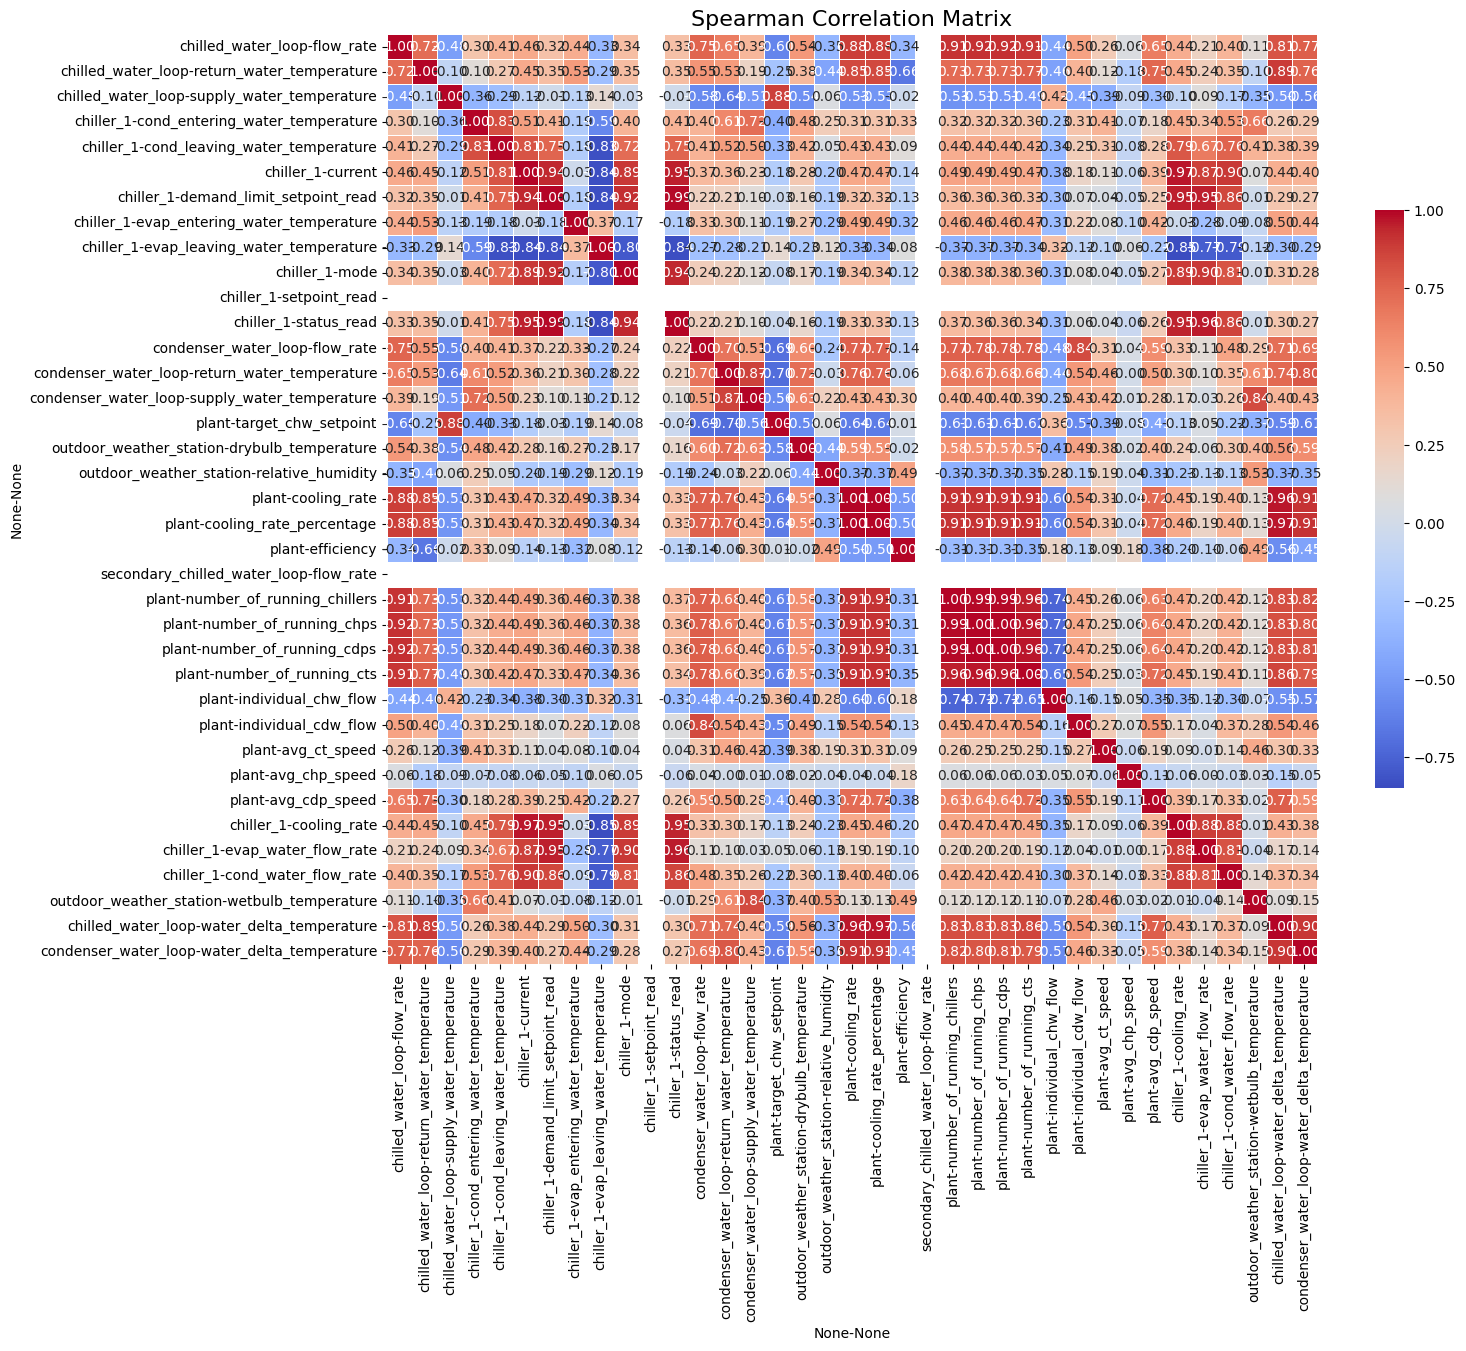

                                         Feature 1  \
0                  (chilled_water_loop, flow_rate)   
1                  (chilled_water_loop, flow_rate)   
2                  (chilled_water_loop, flow_rate)   
3                  (chilled_water_loop, flow_rate)   
4                  (chilled_water_loop, flow_rate)   
..                                             ...   
103                         (plant, avg_cdp_speed)   
104                      (chiller_1, cooling_rate)   
105                      (chiller_1, cooling_rate)   
106              (chiller_1, evap_water_flow_rate)   
107  (chilled_water_loop, water_delta_temperature)   

                                           Feature 2  Correlation  
0     (chilled_water_loop, return_water_temperature)     0.724945  
1                  (condenser_water_loop, flow_rate)     0.749305  
2                              (plant, cooling_rate)     0.879951  
3                   (plant, cooling_rate_percentage)     0.880134  
4          

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

is_device = ['chiller', 'cdp', 'chp', 'ct']
feature_columns = [col for col in chiller_data.columns if col[0] == 'chiller_1' and col[1] != 'power']
feature_columns = [col for col in chiller_data.columns 
                   if (col[0].split('_')[0] not in is_device and 'power' not in col[1]) 
                   or col in feature_columns]

# Check the number of selected feature columns
num_features = len(feature_columns)
print(f"Number of feature columns: {num_features}")

# Extract the feature data
features_data = chiller_data[feature_columns]

# Calculate the Spearman correlation matrix
spearman_corr_matrix = features_data.corr(method='spearman')

# Display the Spearman correlation matrix
print(spearman_corr_matrix)

# Set up the matplotlib figure
plt.figure(figsize=(15, 15))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(spearman_corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=.5, cbar_kws={"shrink": .5})

# Set the title
plt.title('Spearman Correlation Matrix', size=16)

# Show the plot
plt.show()

# Find pairs with absolute correlation greater than 0.7
threshold = 0.7
high_corr_pairs = []

for i in range(len(spearman_corr_matrix.columns)):
    for j in range(i + 1, len(spearman_corr_matrix.columns)):
        corr_value = spearman_corr_matrix.iloc[i, j]
        if abs(corr_value) > threshold:
            feature_pair = (spearman_corr_matrix.columns[i], spearman_corr_matrix.columns[j], corr_value)
            high_corr_pairs.append(feature_pair)

# Convert to DataFrame for better readability
high_corr_pairs_df = pd.DataFrame(high_corr_pairs, columns=['Feature 1', 'Feature 2', 'Correlation'])

print(high_corr_pairs_df)

Number of feature columns: 12
                                                                chiller_1  \
                                          cond_entering_water_temperature   
chiller_1 cond_entering_water_temperature                        1.000000   
          cond_leaving_water_temperature                         0.830277   
          current                                                0.510609   
          demand_limit_setpoint_read                             0.412921   
          evap_entering_water_temperature                       -0.186744   
          evap_leaving_water_temperature                        -0.591974   
          mode                                                   0.402507   
          setpoint_read                                               NaN   
          status_read                                            0.414979   
          cooling_rate                                           0.453098   
          evap_water_flow_rate                

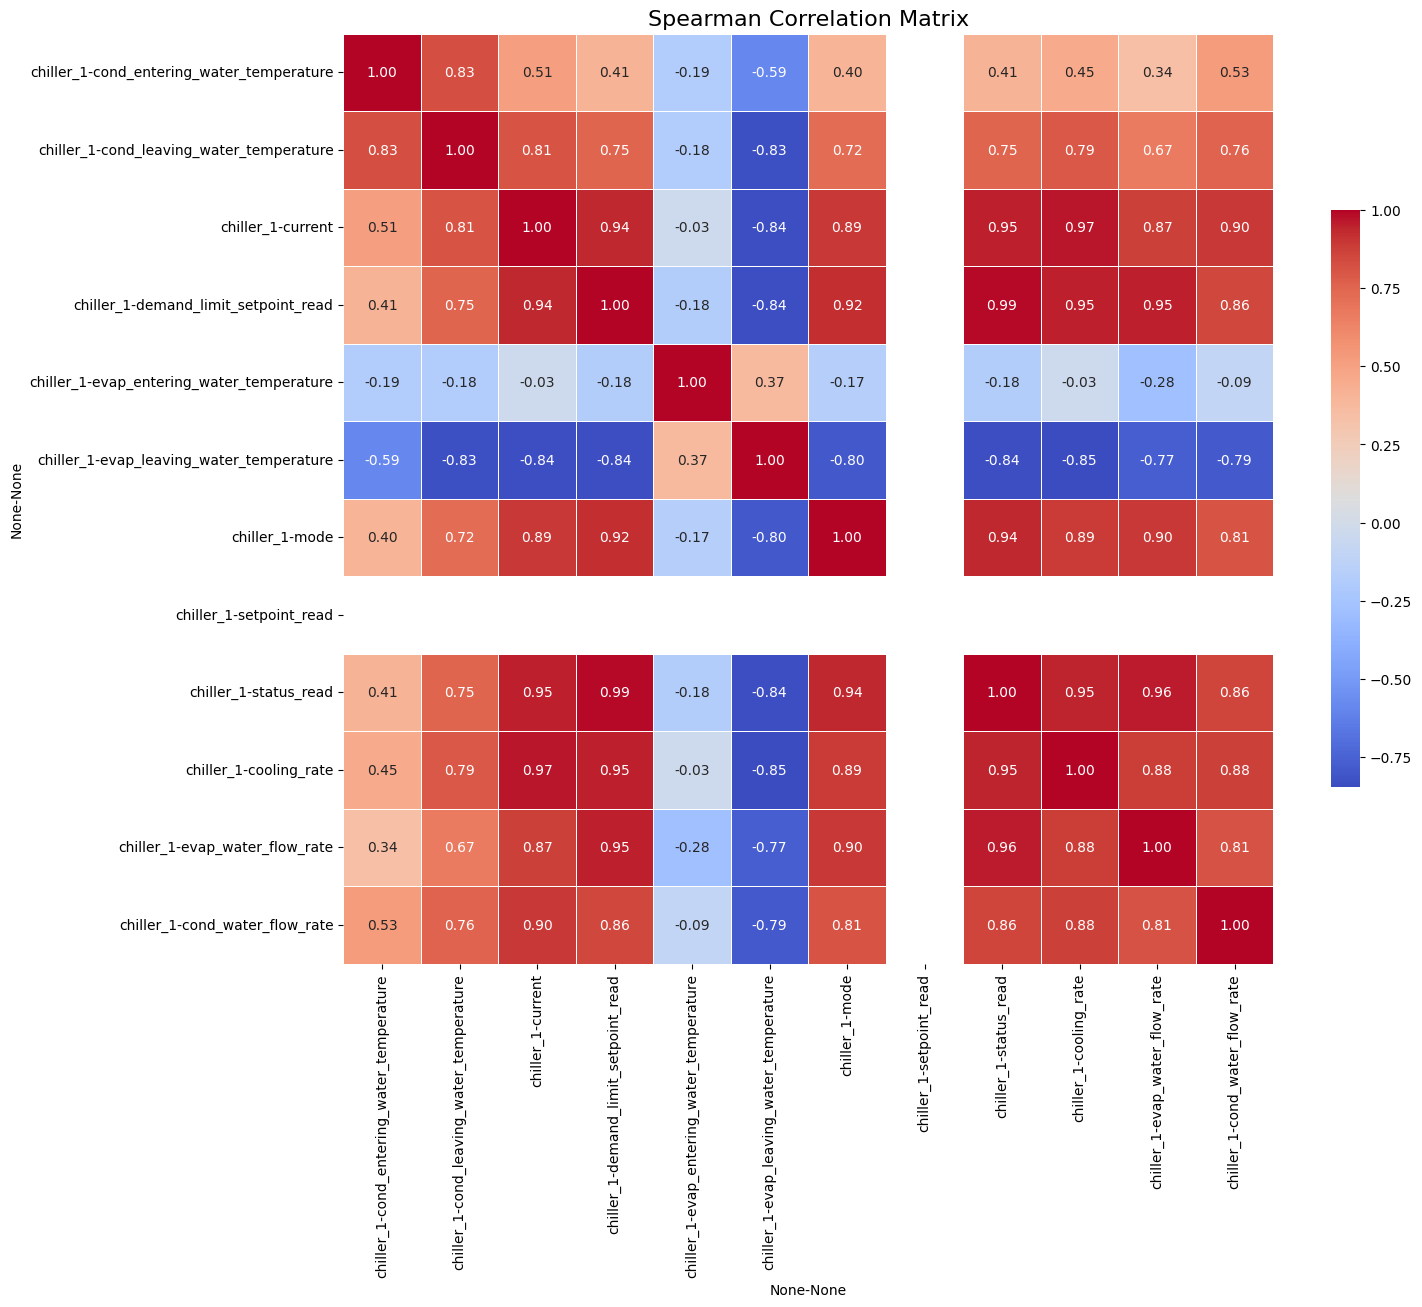

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

is_device = ['chiller', 'cdp', 'chp', 'ct']
feature_columns = [col for col in chiller_data.columns 
                   if col[0] == 'chiller_1' and col[1] != 'power']

# Check the number of selected feature columns
num_features = len(feature_columns)
print(f"Number of feature columns: {num_features}")

# Extract the feature data
features_data = chiller_data[feature_columns]

# Calculate the Spearman correlation matrix
spearman_corr_matrix = features_data.corr(method='spearman')

# Display the Spearman correlation matrix
print(spearman_corr_matrix)

# Set up the matplotlib figure
plt.figure(figsize=(15, 15))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(spearman_corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=.5, cbar_kws={"shrink": .5})

# Set the title
plt.title('Spearman Correlation Matrix', size=16)

# Show the plot
plt.show()

#### Correlation to power

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



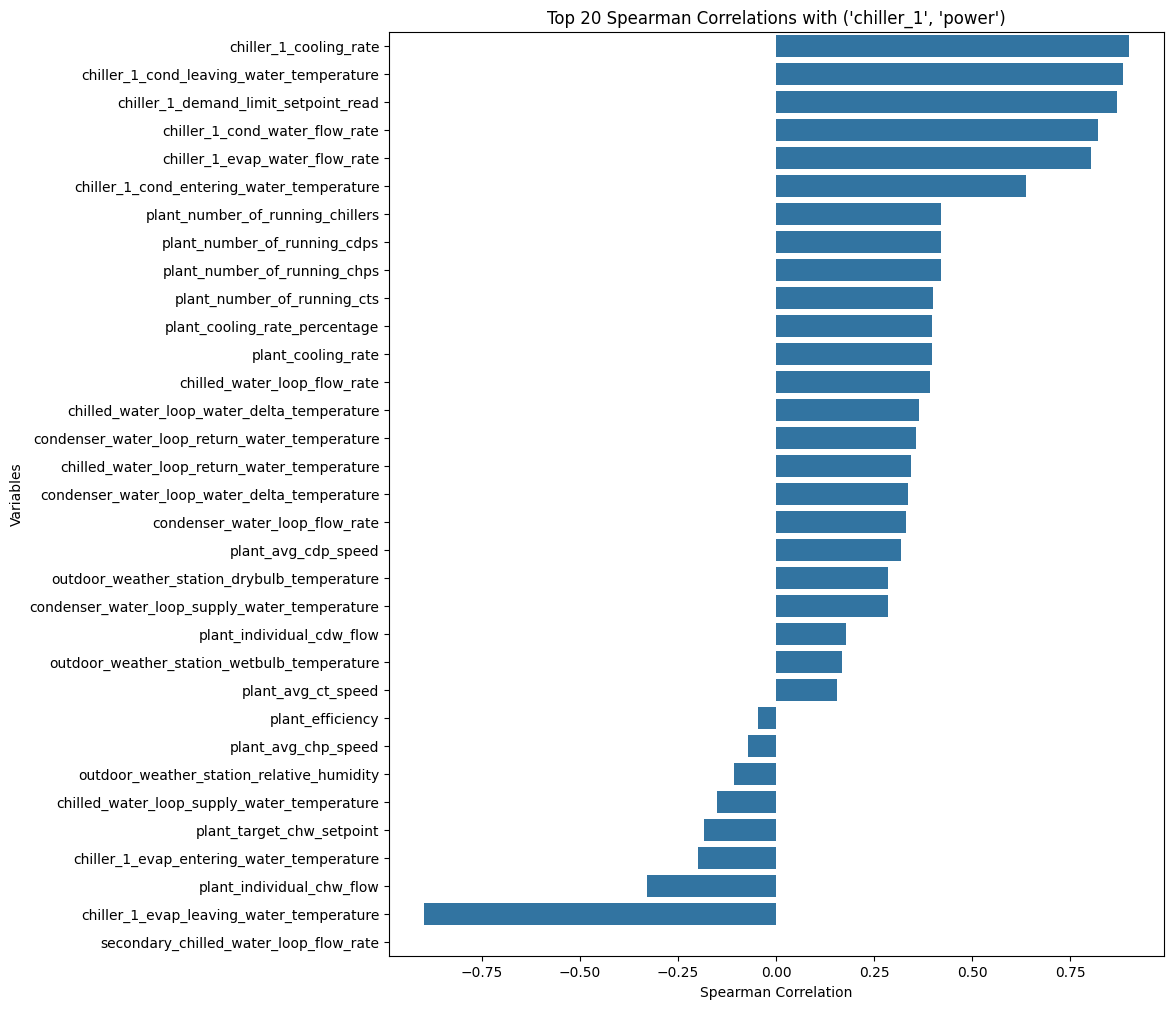

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



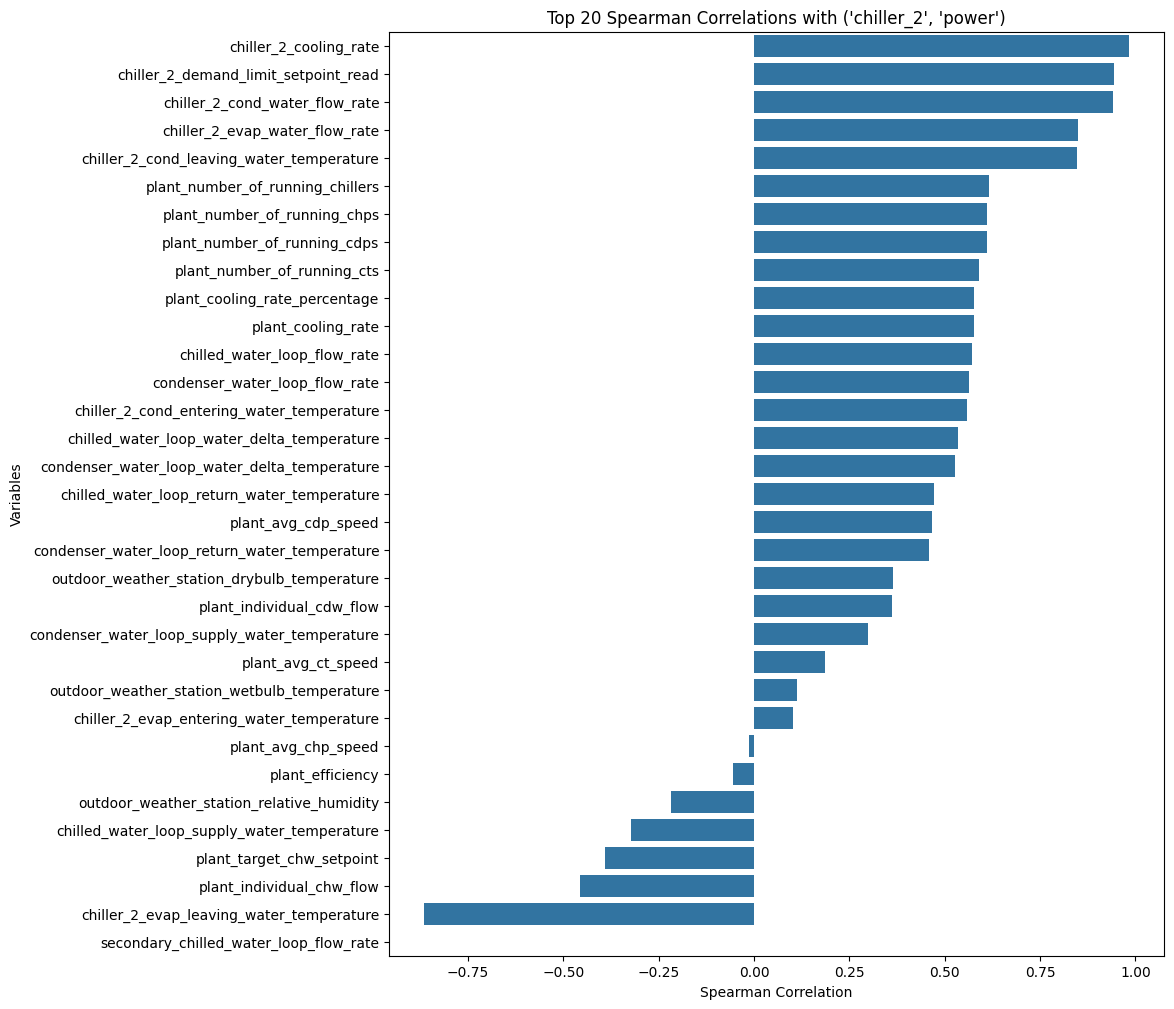

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



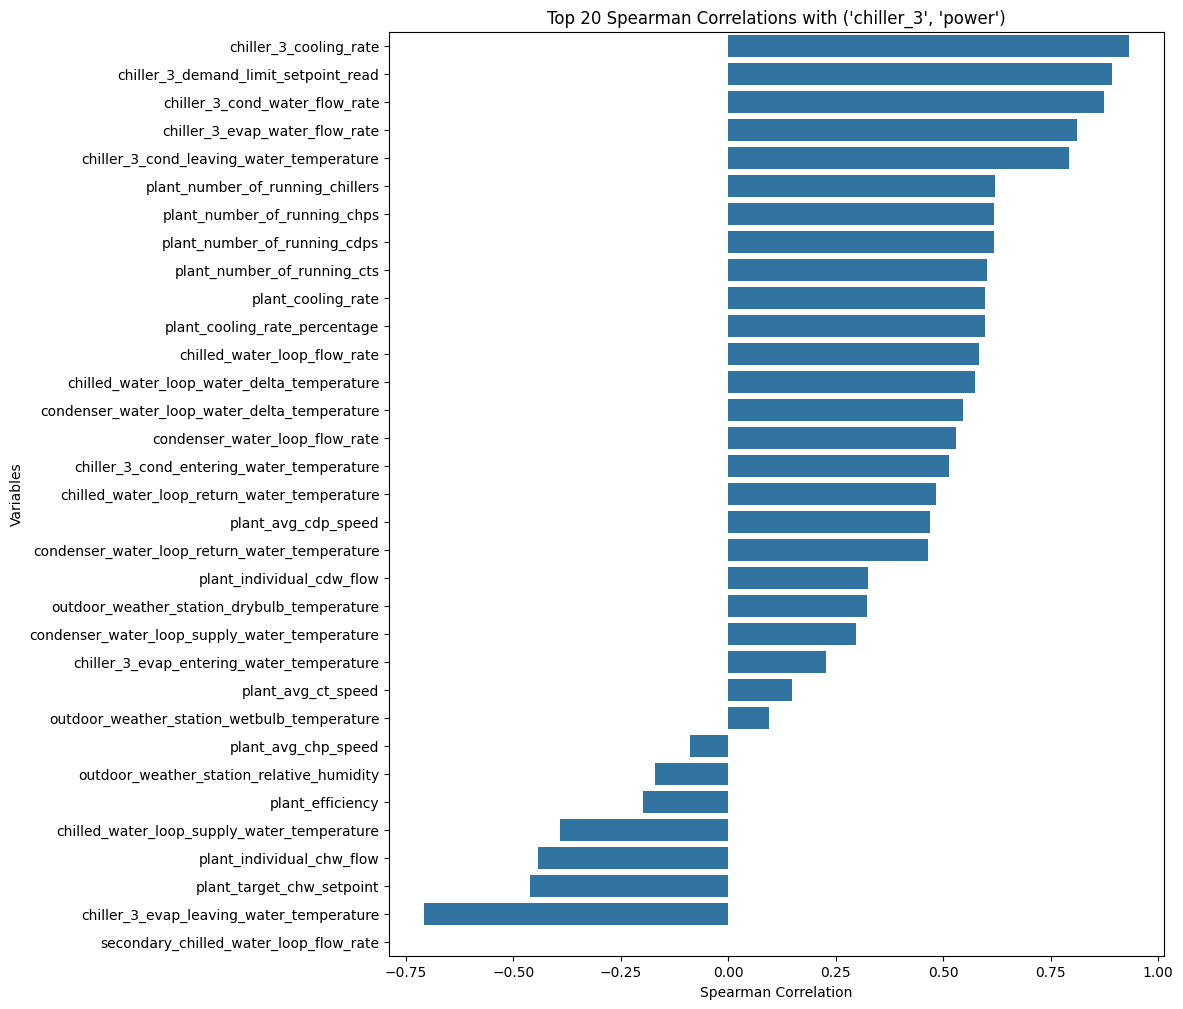

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



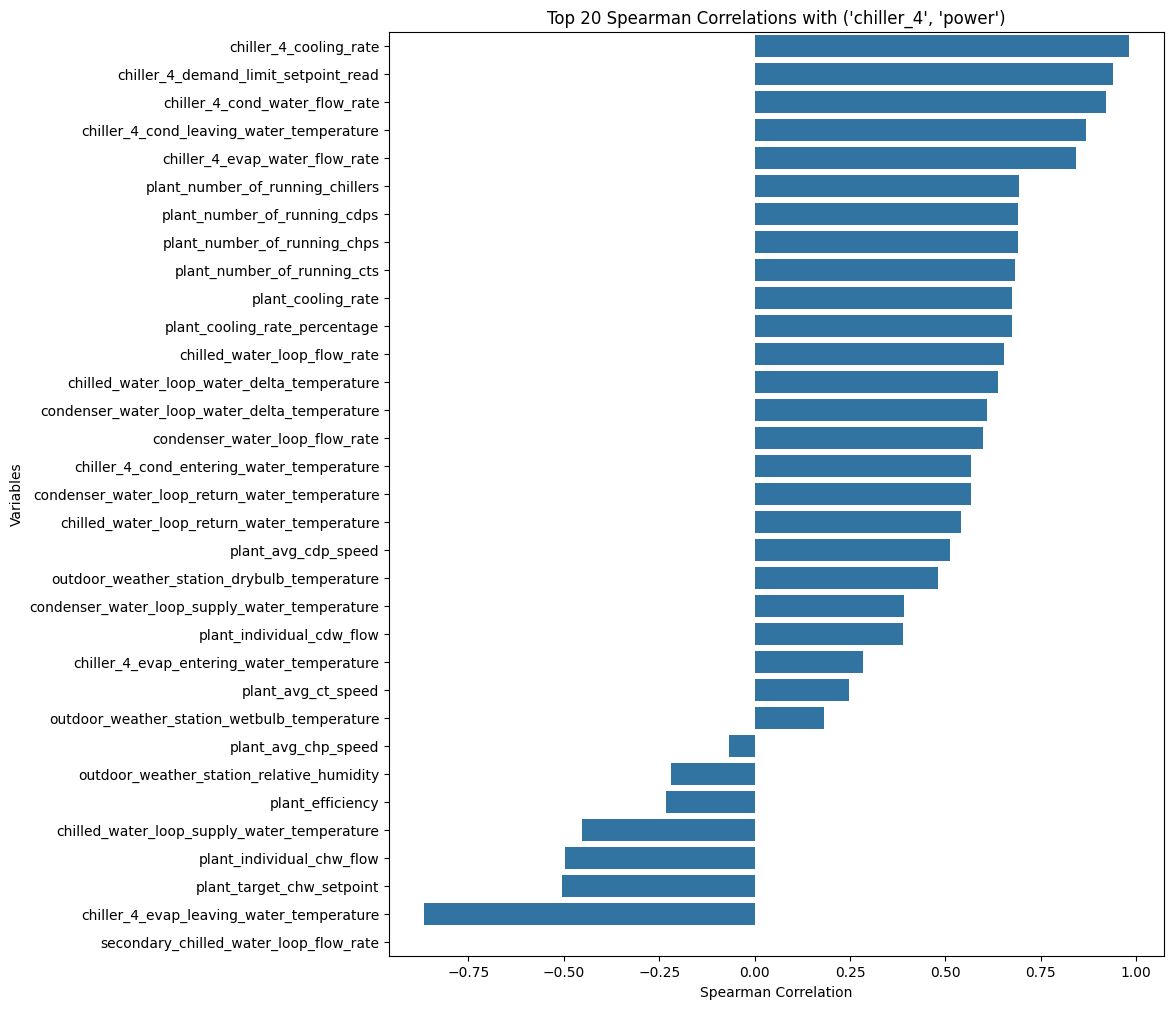

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



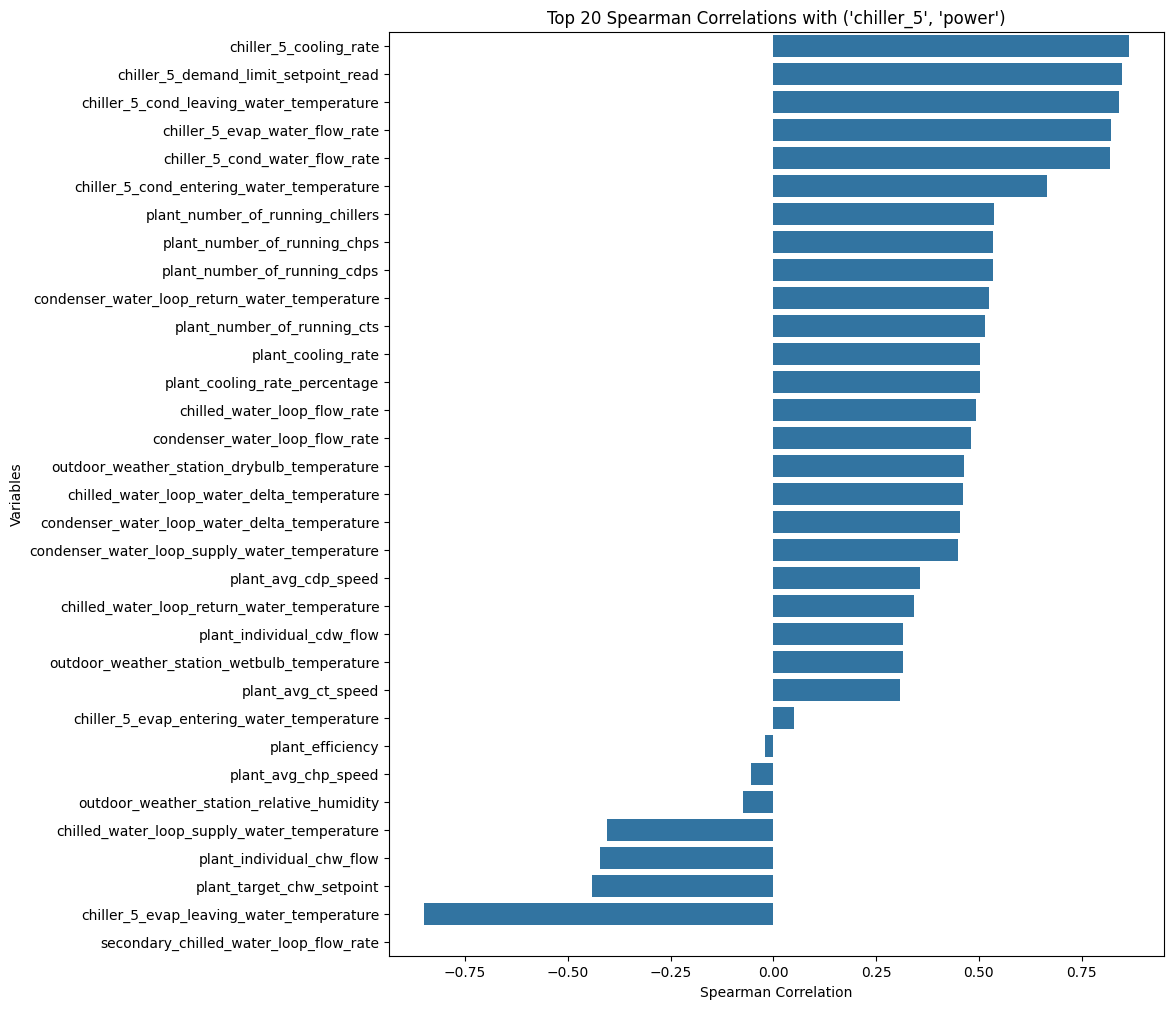

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Define the list of power columns
power_columns = [col for col in chiller_data.columns if 'chiller' in col[0] and 'power' in col[1]]

is_device = ['chiller', 'cdp', 'chp', 'ct']
drop_properties = ['status_read', 'mode', 'current', 'setpoint_read']

# Calculate and plot top 20 Spearman correlations for each power column
for power_col in power_columns:
    compare_columns = [ccol for ccol in chiller_data.columns if (ccol[0] == power_col[0] or ccol[0].split('_')[0] not in is_device)
                       and 'power' not in ccol[1]]
    compare_columns = [ccol for ccol in compare_columns if ccol[1] not in drop_properties]
    
    X = chiller_data[compare_columns]
    y = chiller_data[power_col]
    
    # Calculate Spearman correlation
    correlations = X.apply(lambda col: col.corr(y, method='spearman'))
    corr_series = correlations.sort_values(ascending=False)
    corr_series.index = ['_'.join(col) if isinstance(col, tuple) else col for col in corr_series.index]
    
    plt.figure(figsize=(10, 12))
    sns.barplot(x=corr_series.values, y=corr_series.index)
    plt.title(f'Top 20 Spearman Correlations with {power_col}')
    plt.xlabel('Spearman Correlation')
    plt.ylabel('Variables')
    plt.show()

#### Corr Chiller_1

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



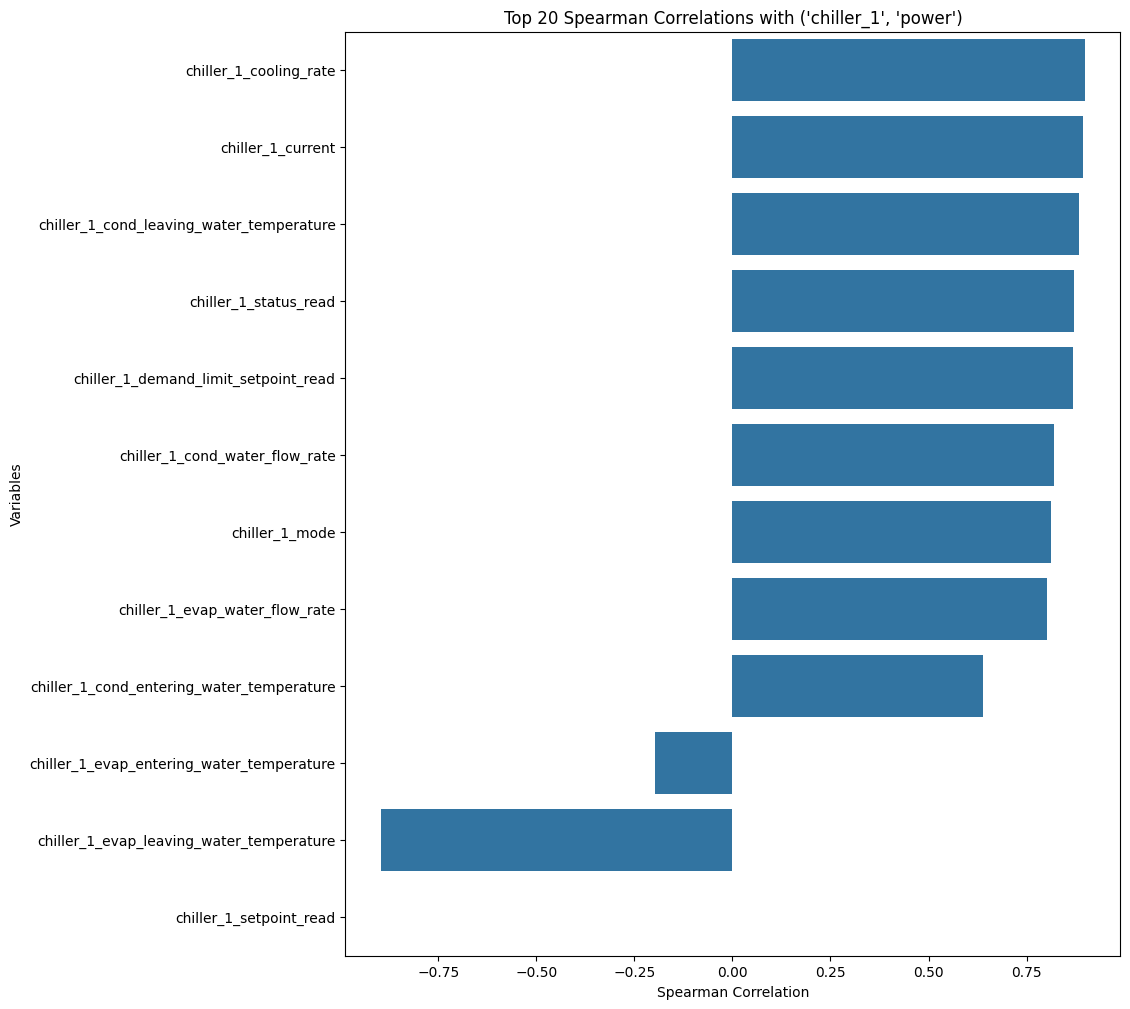

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



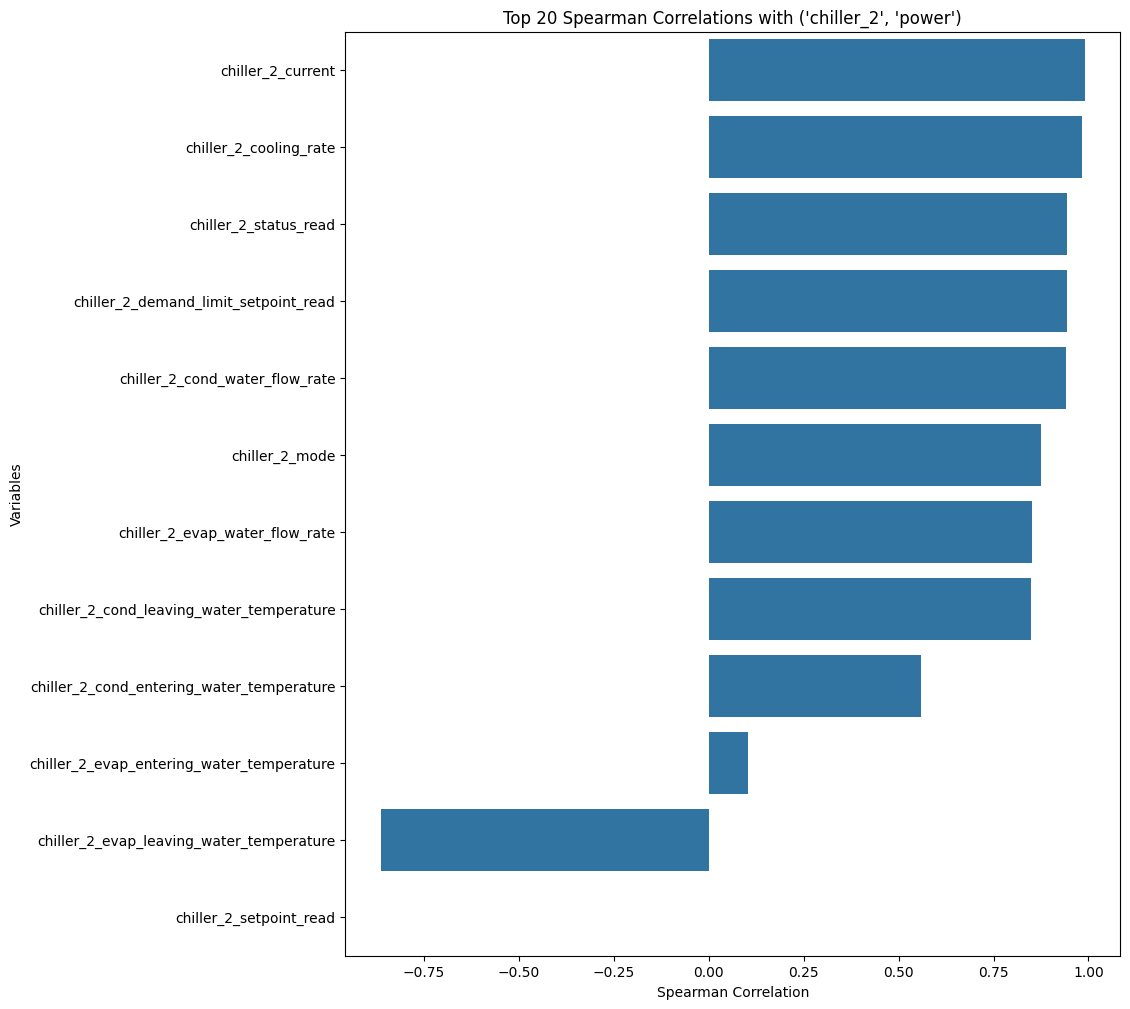

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



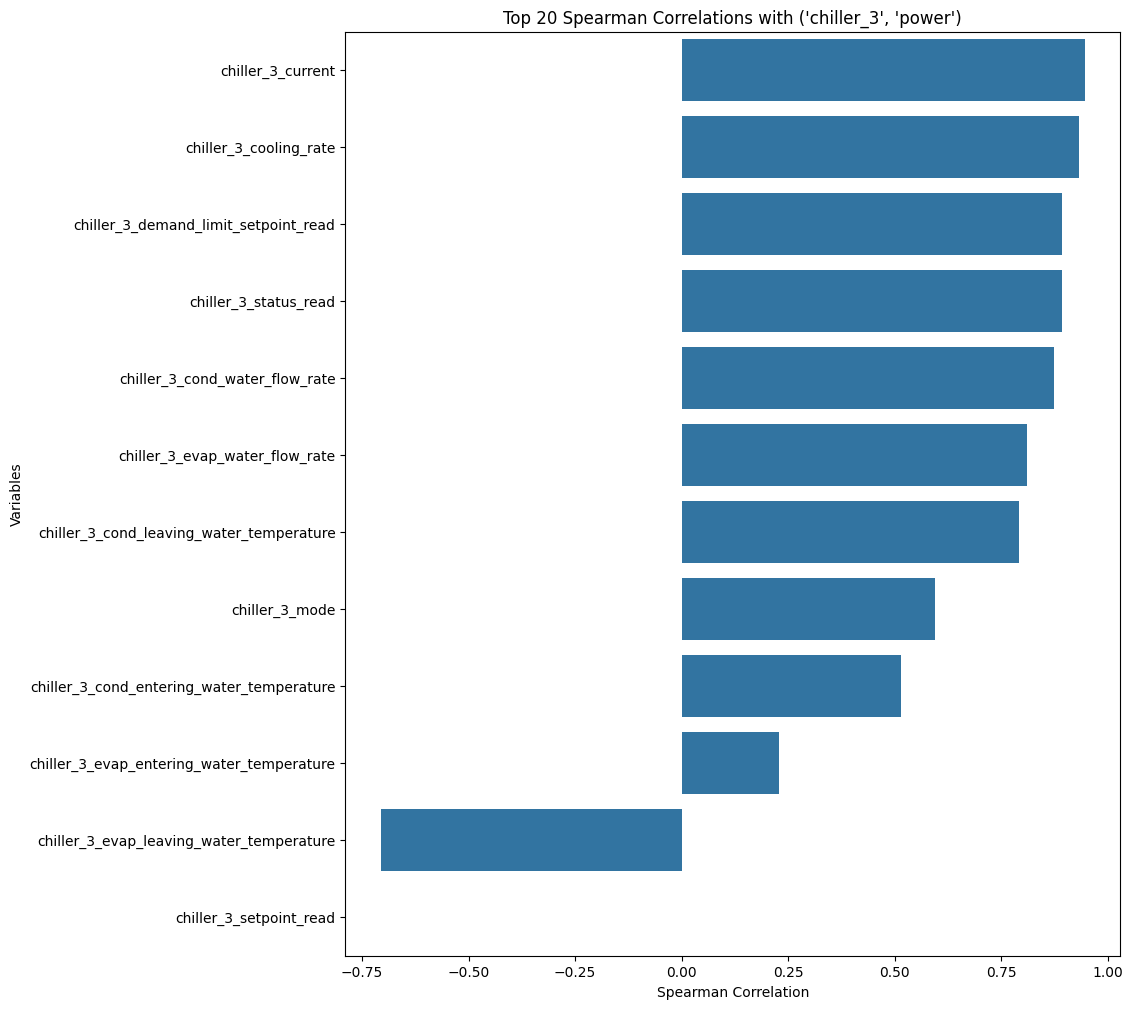

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



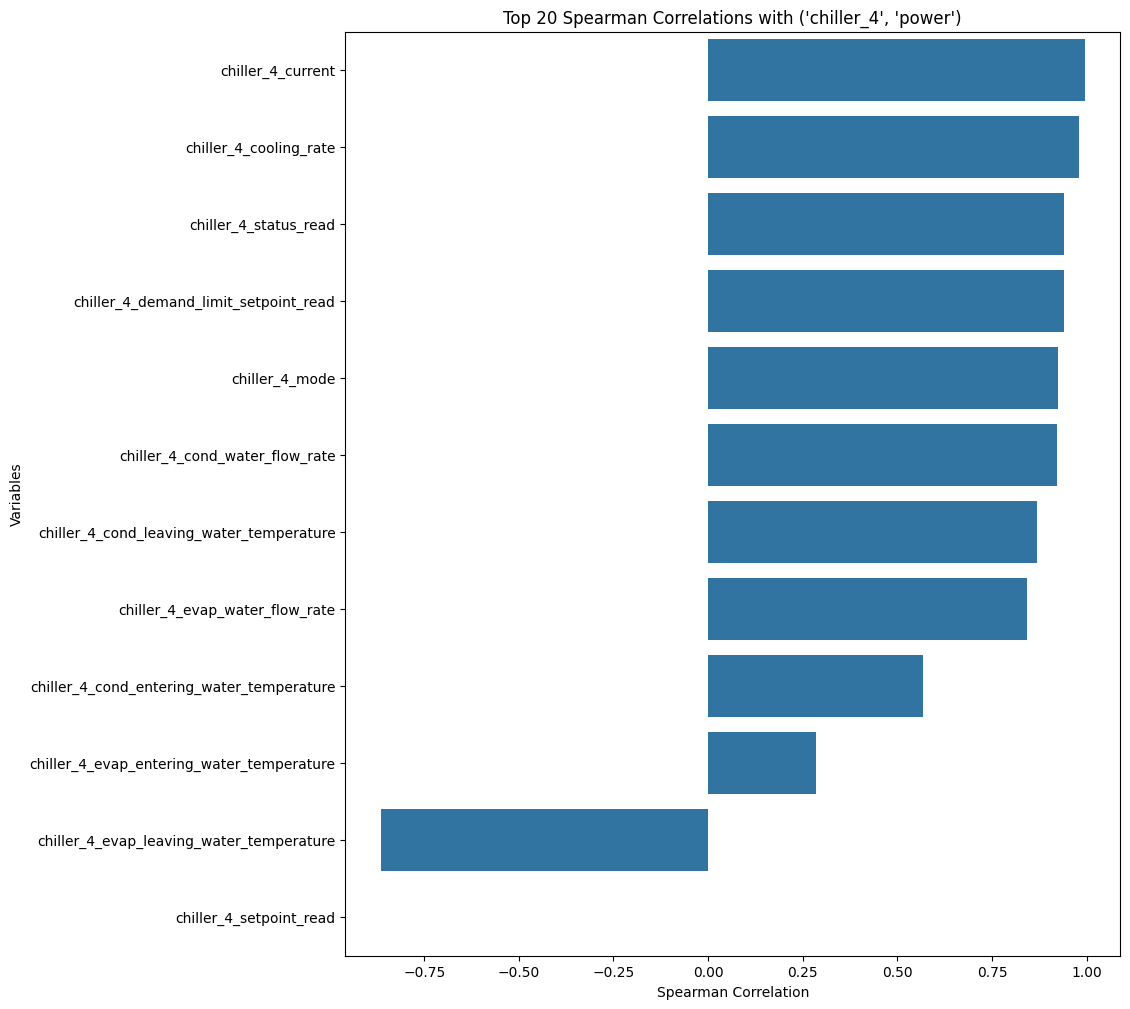

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



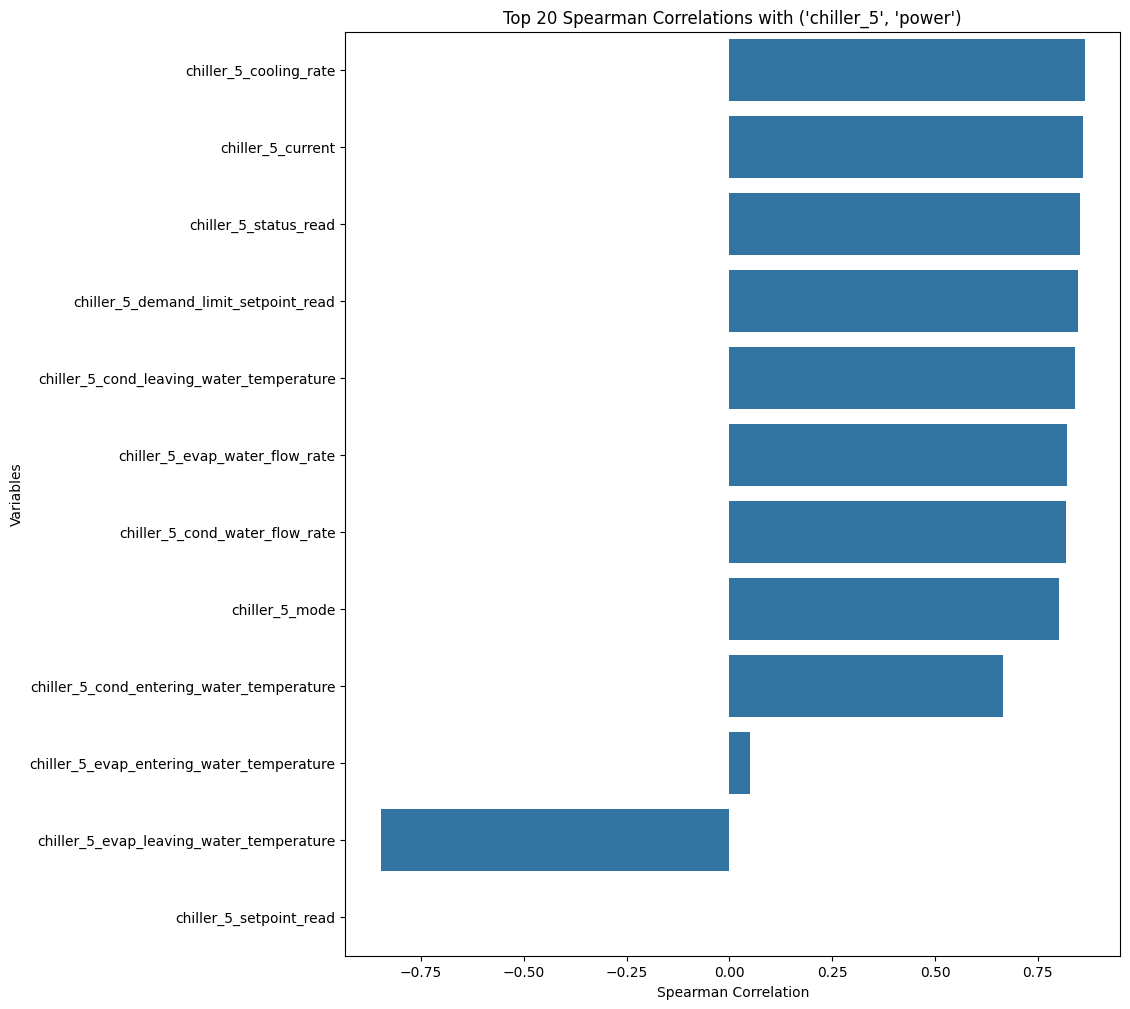

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Define the list of power columns
power_columns = [col for col in chiller_data.columns if 'chiller' in col[0] and 'power' in col[1]]


# Calculate and plot top 20 Spearman correlations for each power column
for power_col in power_columns:
    compare_columns = [ccol for ccol in chiller_data.columns if ccol[0]==power_col[0]
                       and 'power' not in ccol[1]]
    
    X = chiller_data[compare_columns]
    y = chiller_data[power_col]
    
    # Calculate Spearman correlation
    correlations = X.apply(lambda col: col.corr(y, method='spearman'))
    corr_series = correlations.sort_values(ascending=False)
    corr_series.index = ['_'.join(col) if isinstance(col, tuple) else col for col in corr_series.index]
    
    plt.figure(figsize=(10, 12))
    sns.barplot(x=corr_series.values, y=corr_series.index)
    plt.title(f'Top 20 Spearman Correlations with {power_col}')
    plt.xlabel('Spearman Correlation')
    plt.ylabel('Variables')
    plt.show()

#### Mutual Information

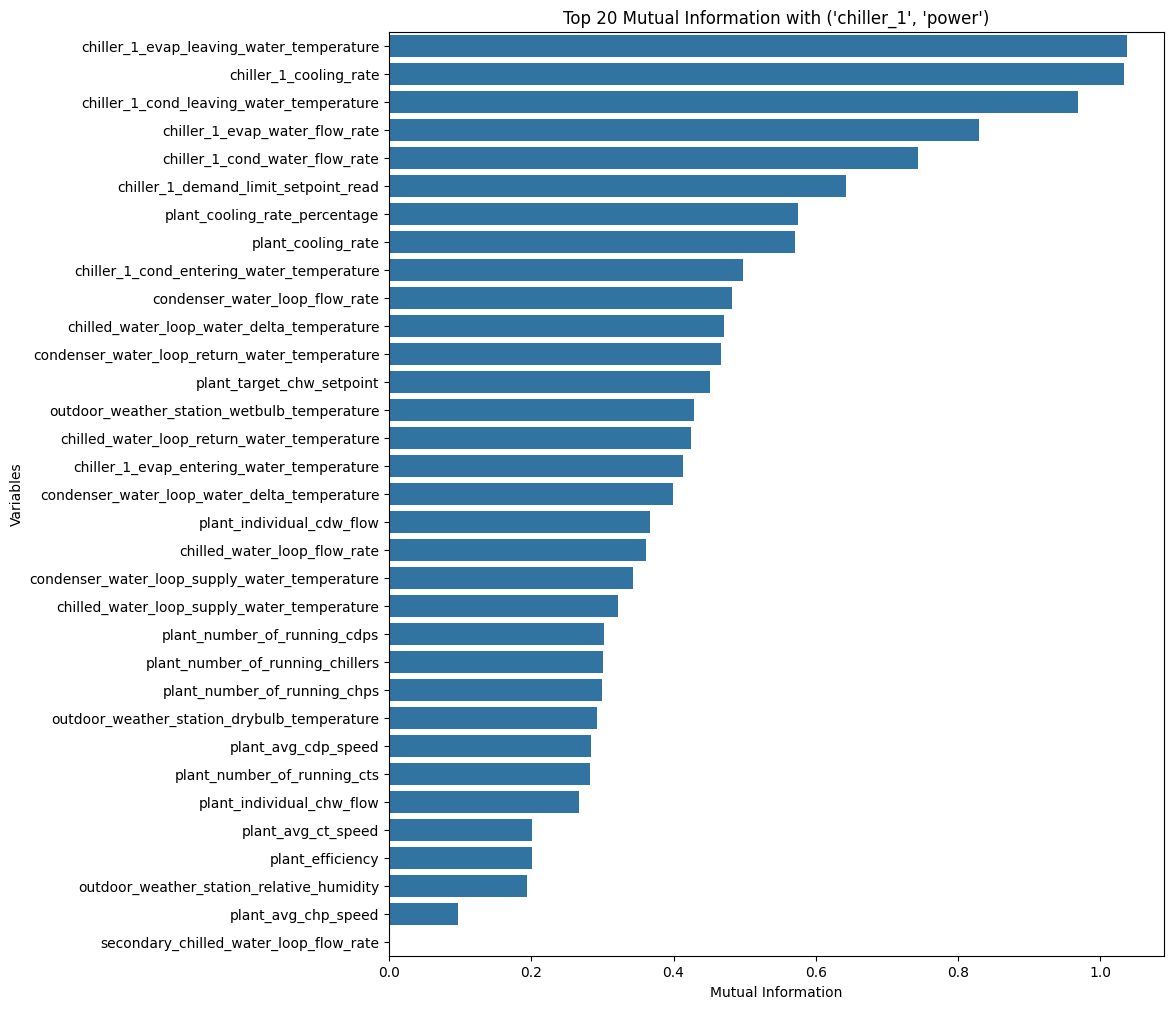

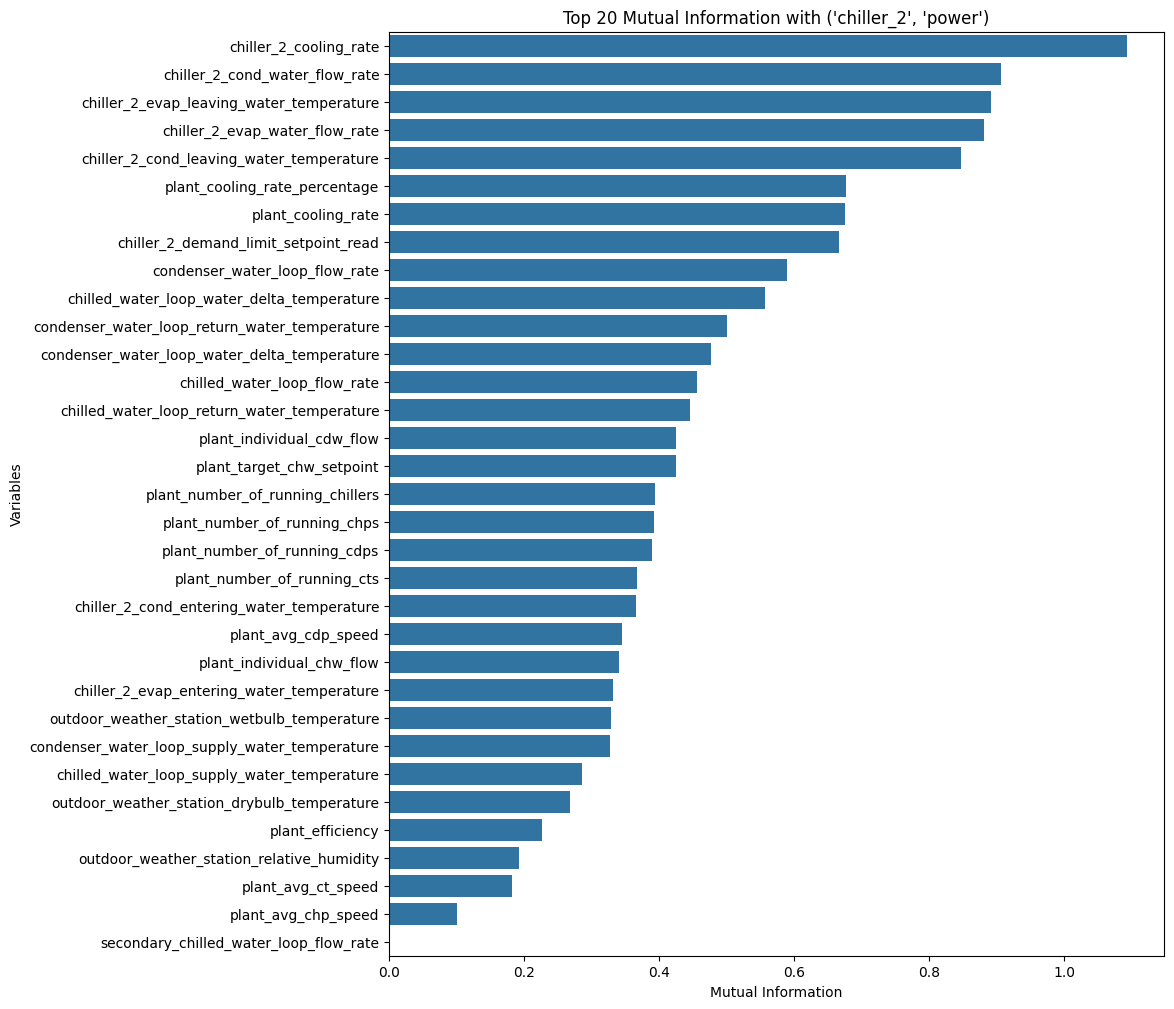

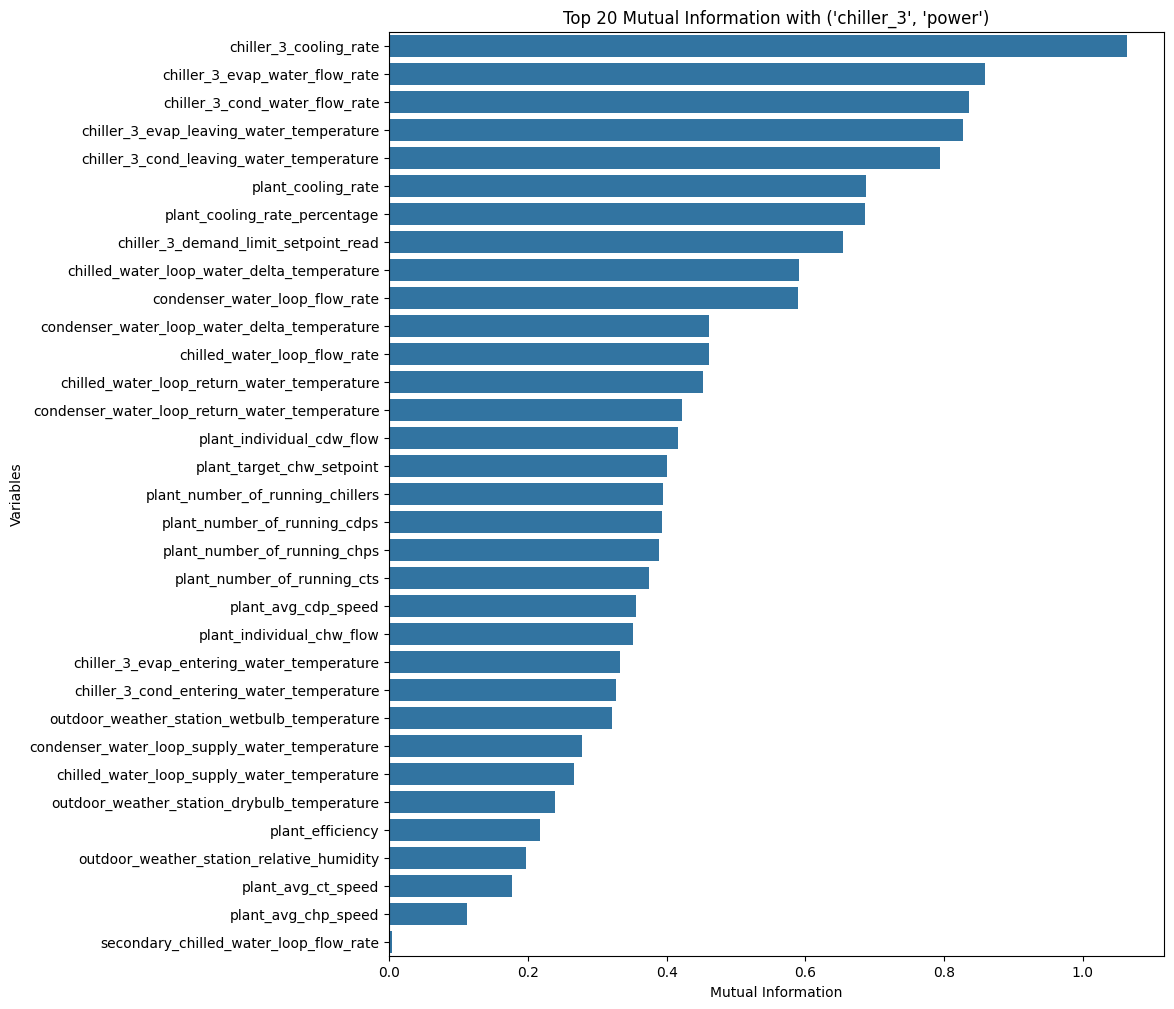

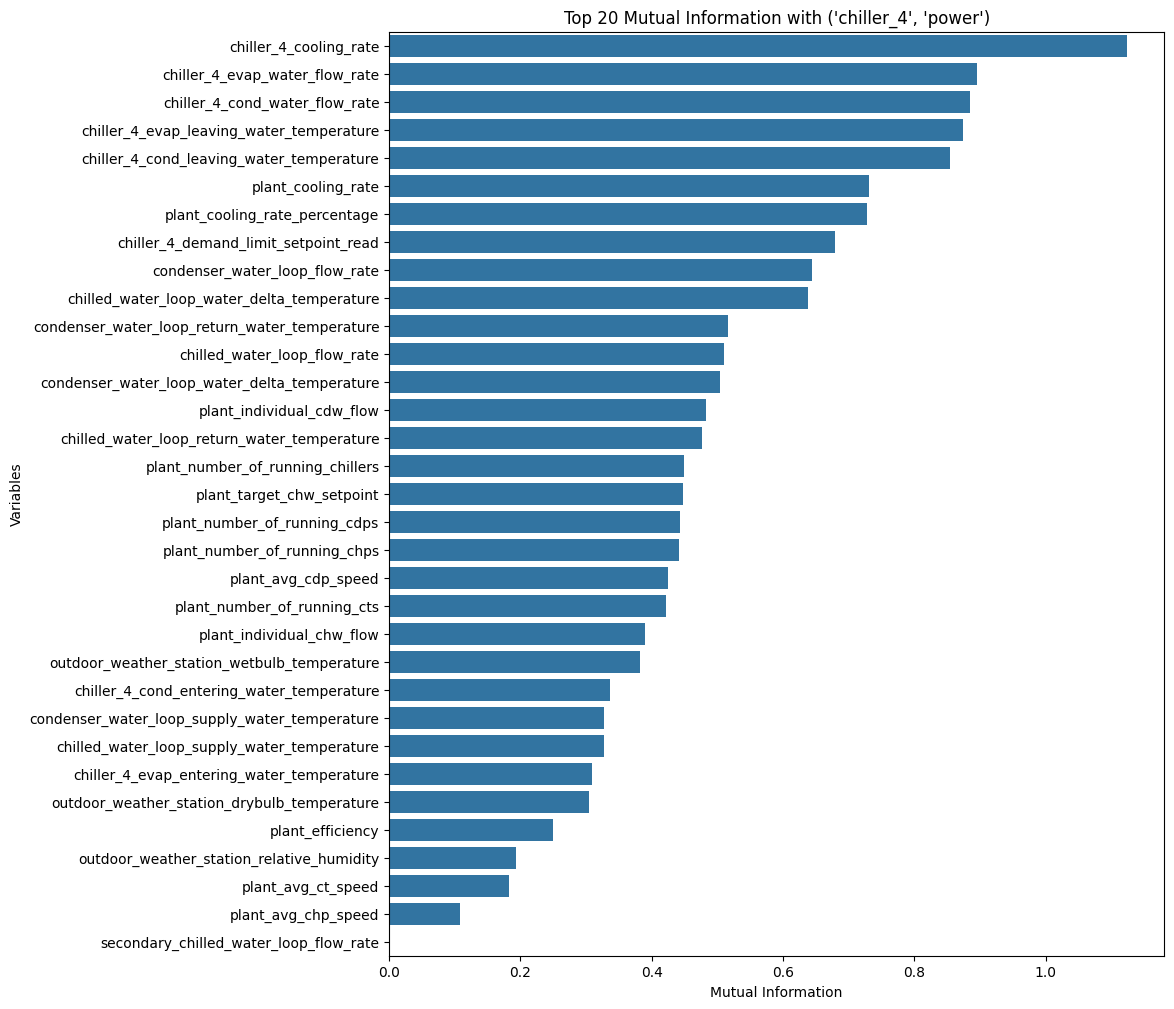

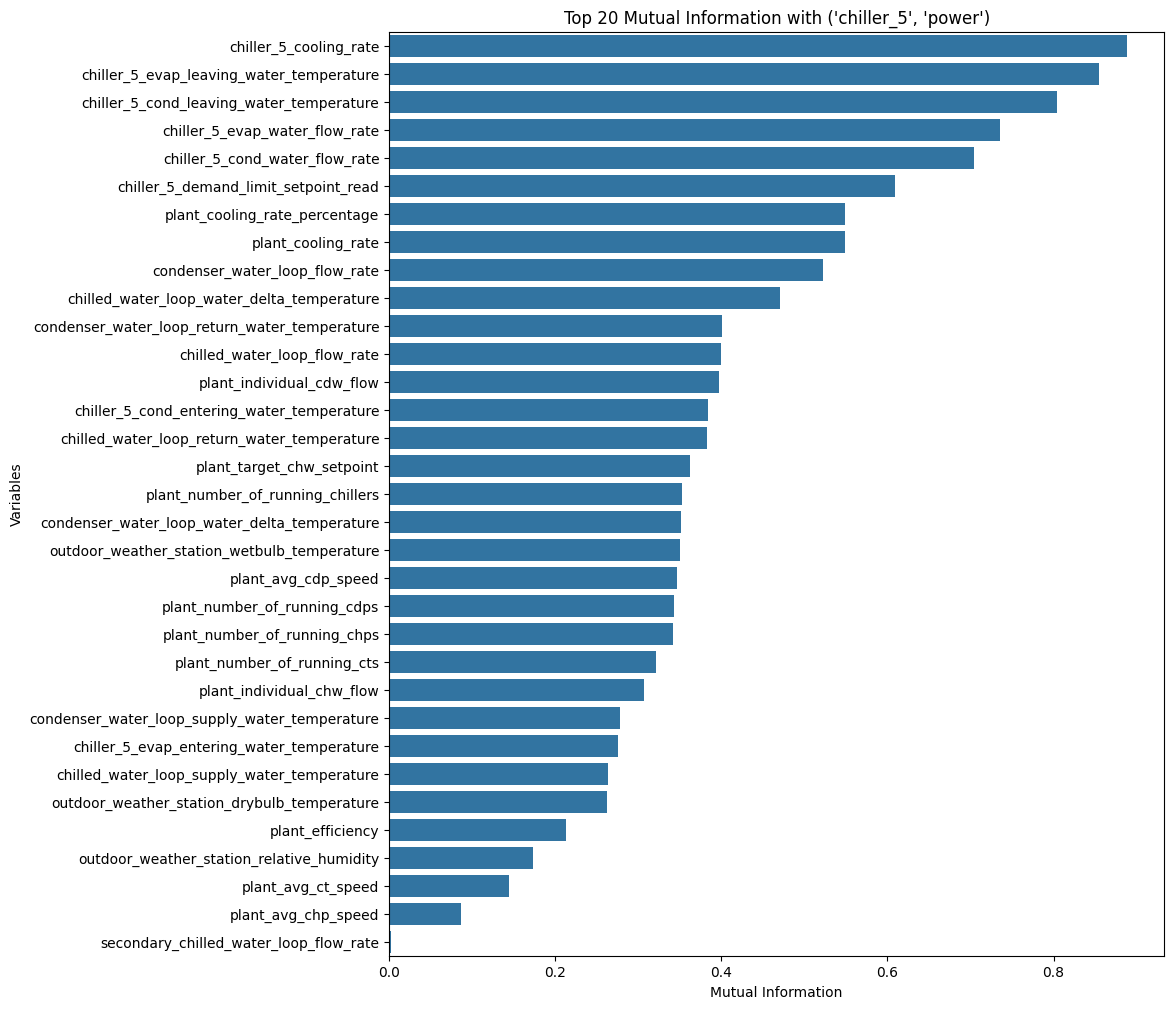

In [40]:
from sklearn.feature_selection import mutual_info_regression
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Define the list of power columns
power_columns = [col for col in chiller_data.columns if 'chiller' in col[0] and 'power' in col[1]]

is_device = ['chiller','cdp','chp','ct']
drop_properties = ['status_read','mode','current','setpoint_read']

# Calculate and plot top 20 mutual information for each power column
for power_col in power_columns:
    compare_columns = [ccol for ccol in chiller_data.columns if (ccol[0]==power_col[0] or ccol[0].split('_')[0] not in is_device)
                       and 'power' not in ccol[1]]
    compare_columns = [ccol for ccol in compare_columns if ccol[1] not in drop_properties]
    X = chiller_data[compare_columns]
    y = chiller_data[power_col]
    
    mi = mutual_info_regression(X, y)
    mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)
    mi_series.index = ['_'.join(col) if isinstance(col, tuple) else col for col in mi_series.index]
    
    plt.figure(figsize=(10, 12))
    sns.barplot(x=mi_series.values, y=mi_series.index)
    plt.title(f'Top 20 Mutual Information with {power_col}')
    plt.xlabel('Mutual Information')
    plt.ylabel('Variables')
    plt.show()

#### Power plot

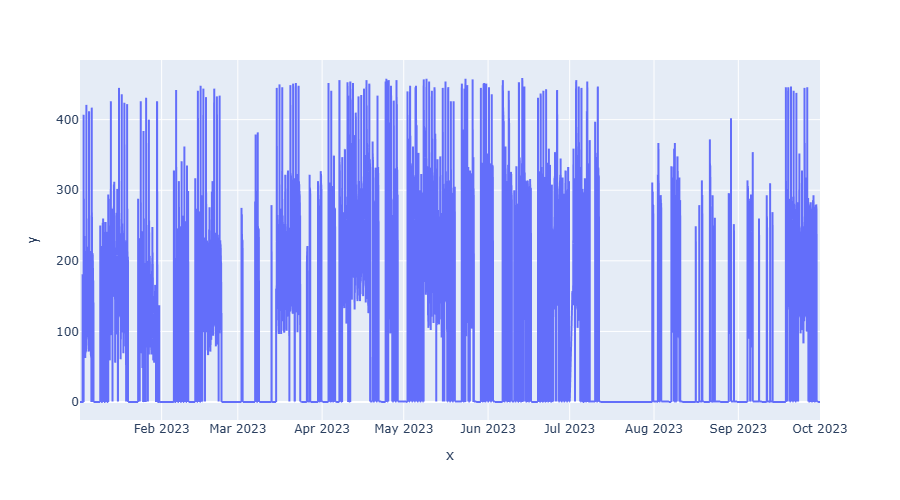

In [41]:
fig = px.line(x=chiller_data.index, y=chiller_data['chiller_1','power'])
fig.show()

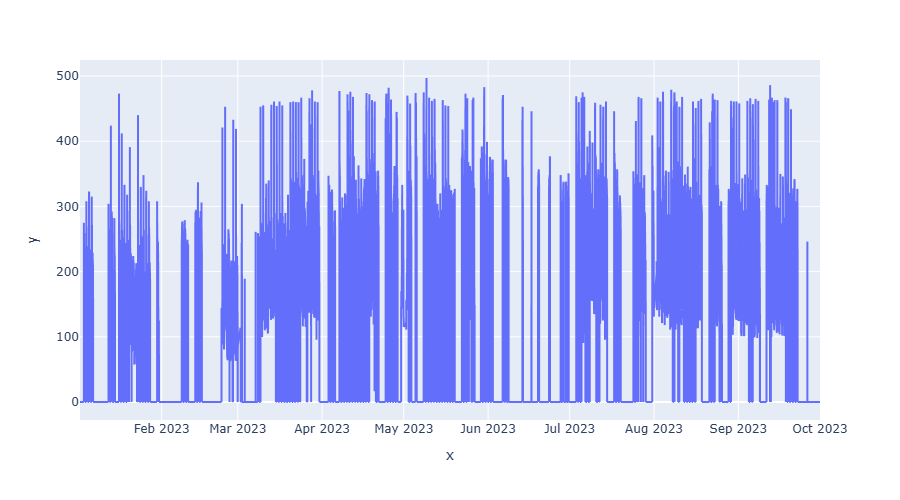

In [42]:
fig = px.line(x=chiller_data.index, y=chiller_data['chiller_2','power'])
fig.show()

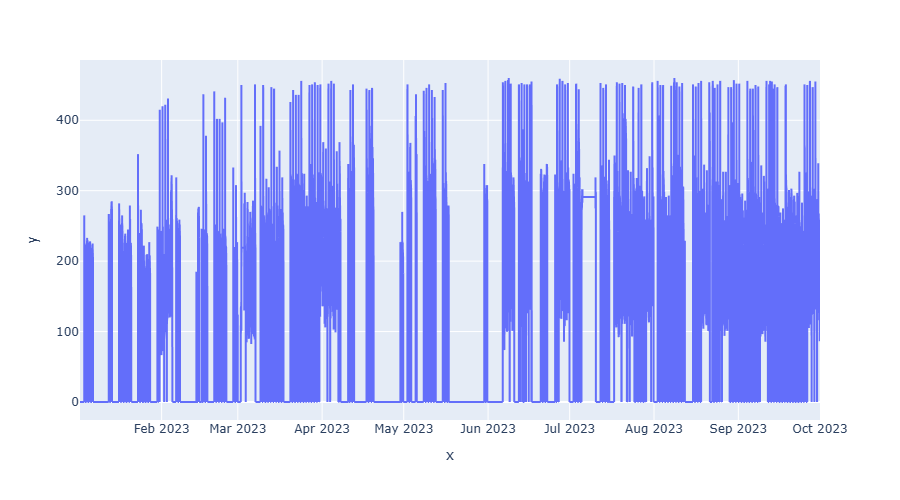

In [43]:
fig = px.line(x=chiller_data.index, y=chiller_data['chiller_3','power'])
fig.show()

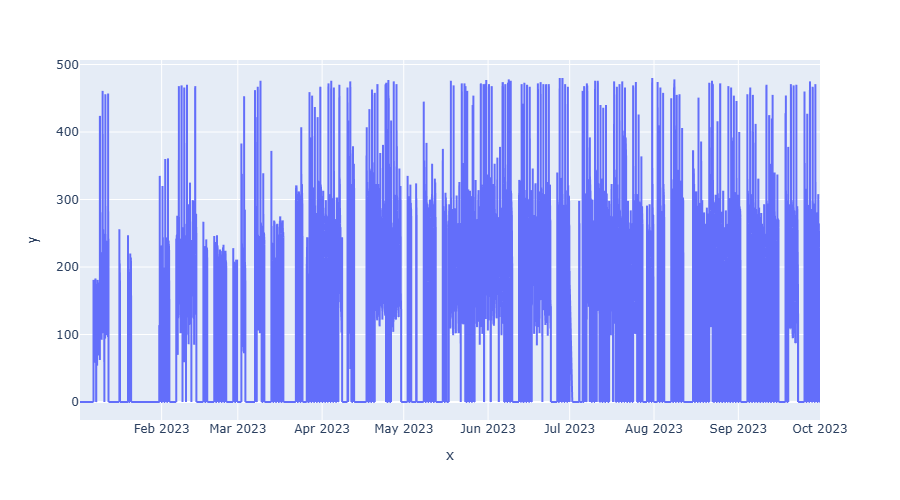

In [44]:
fig = px.line(x=chiller_data.index, y=chiller_data['chiller_4','power'])
fig.show()

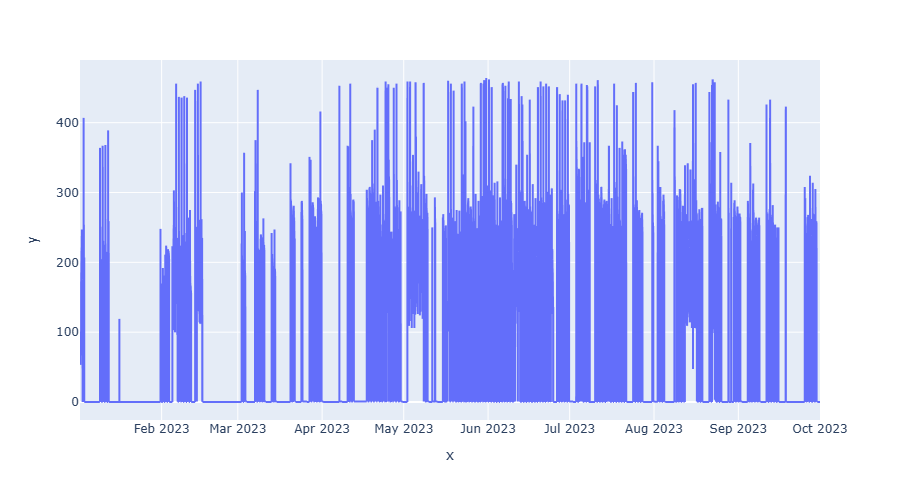

In [45]:
fig = px.line(x=chiller_data.index, y=chiller_data['chiller_5','power'])
fig.show()

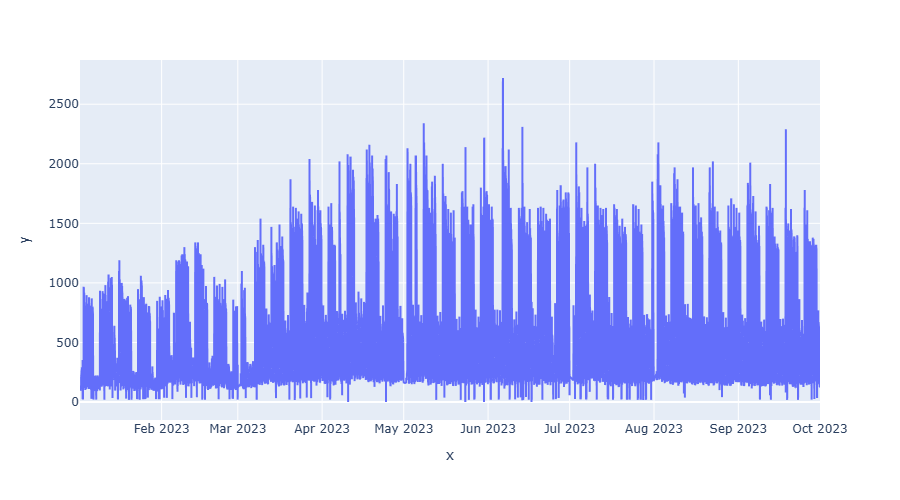

In [46]:
fig = px.line(x=chiller_data.index, y=chiller_data['plant','power'])
fig.show()

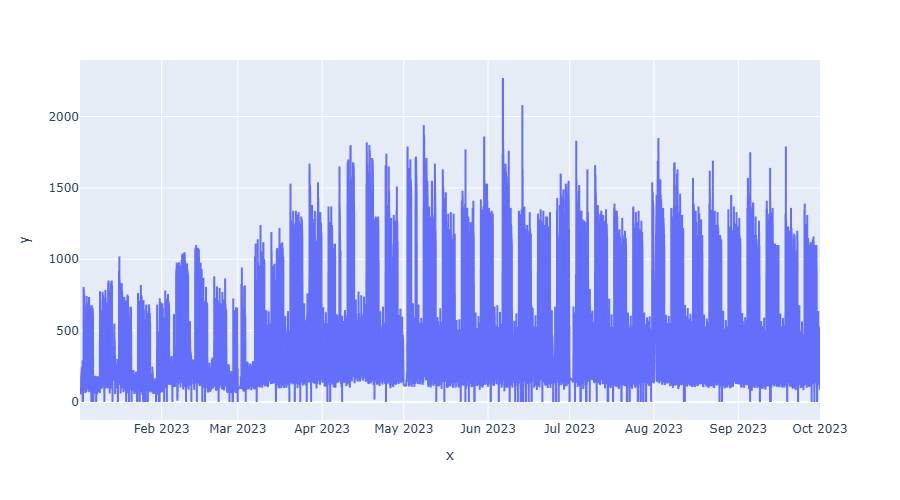

In [47]:
fig = px.line(x=chiller_data.index, y=chiller_data['plant','power_all_chillers'])
fig.show()

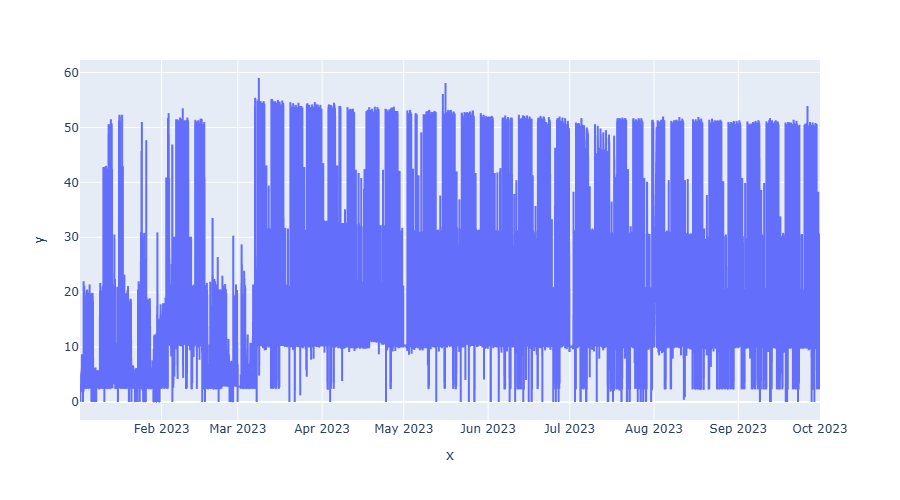

In [48]:
fig = px.line(x=chiller_data.index, y=chiller_data['plant','power_all_cts'])
fig.show()

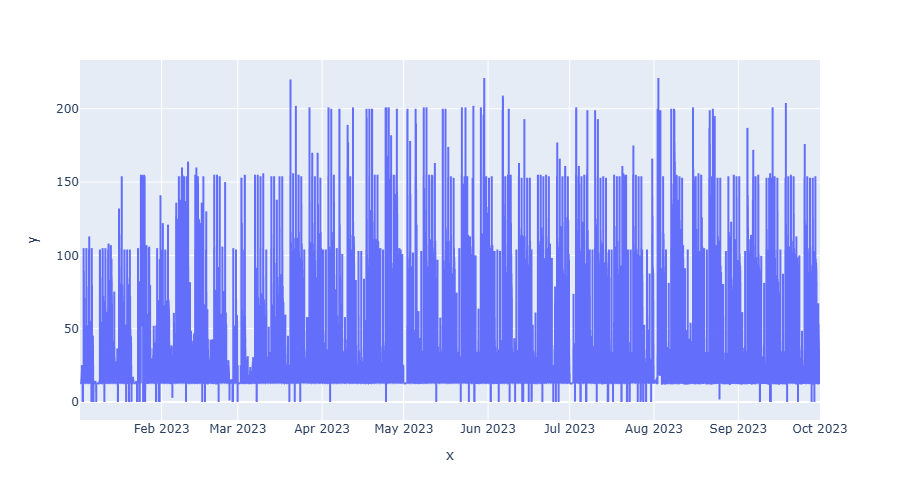

In [49]:
fig = px.line(x=chiller_data.index, y=chiller_data['plant','power_all_cdps'])
fig.show()

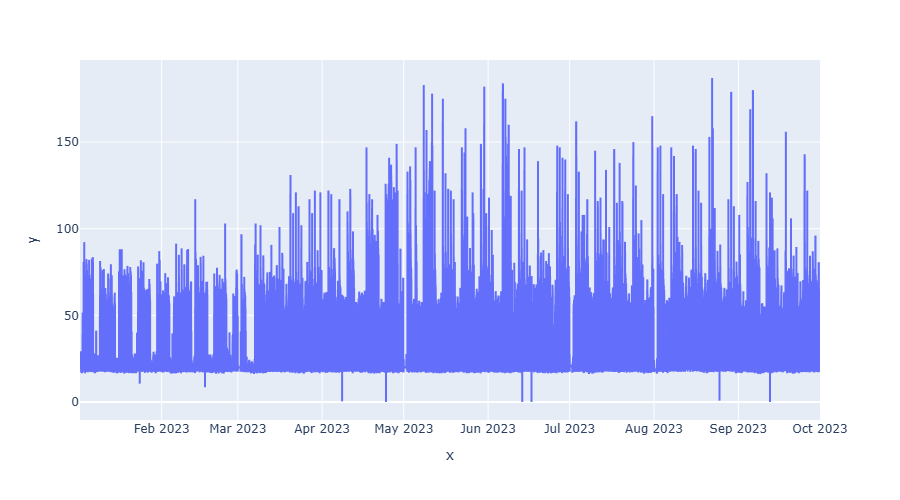

In [50]:
fig = px.line(x=chiller_data.index, y=chiller_data['plant','power_all_chps'])
fig.show()

#### Corr plant power

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



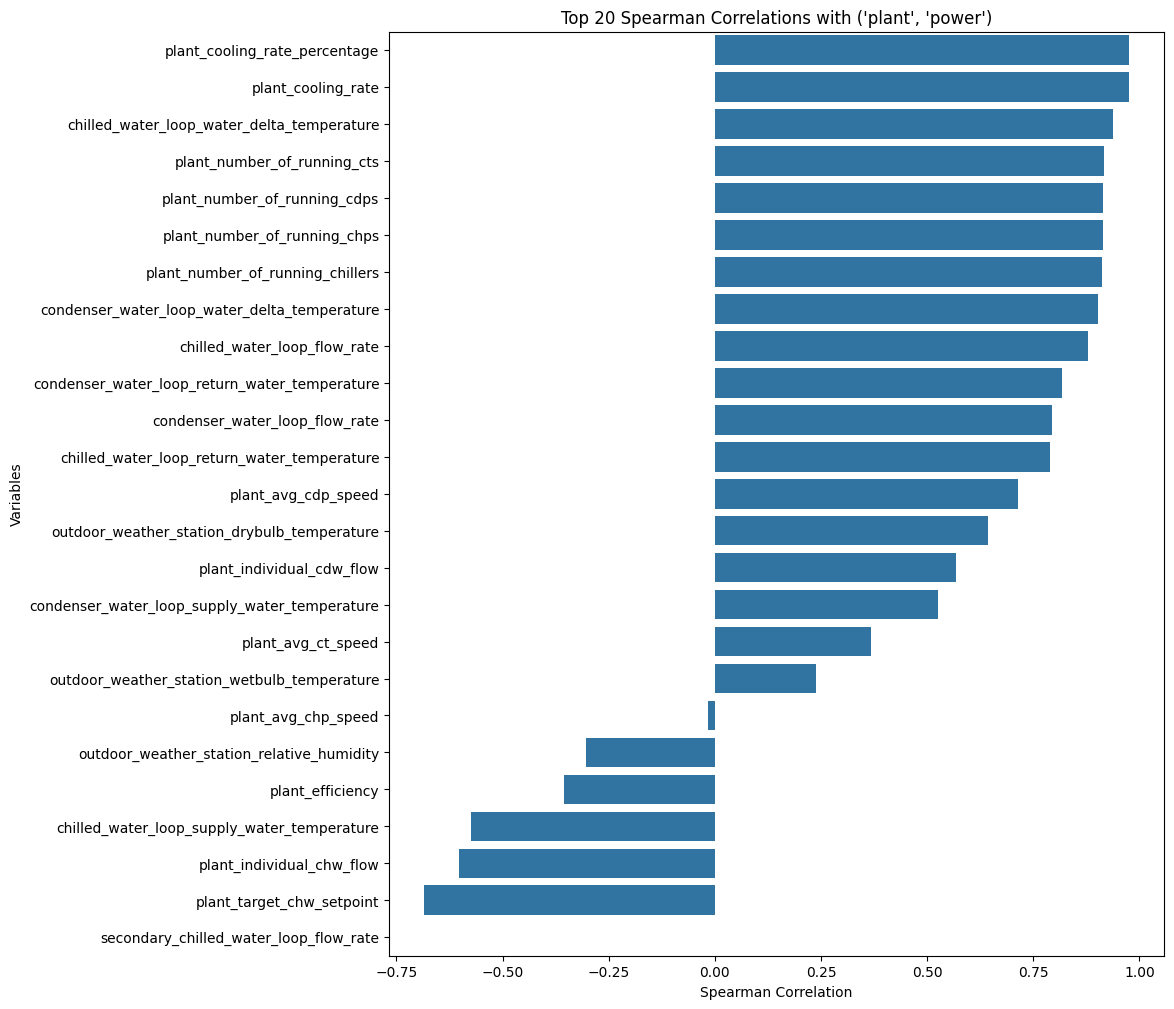

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



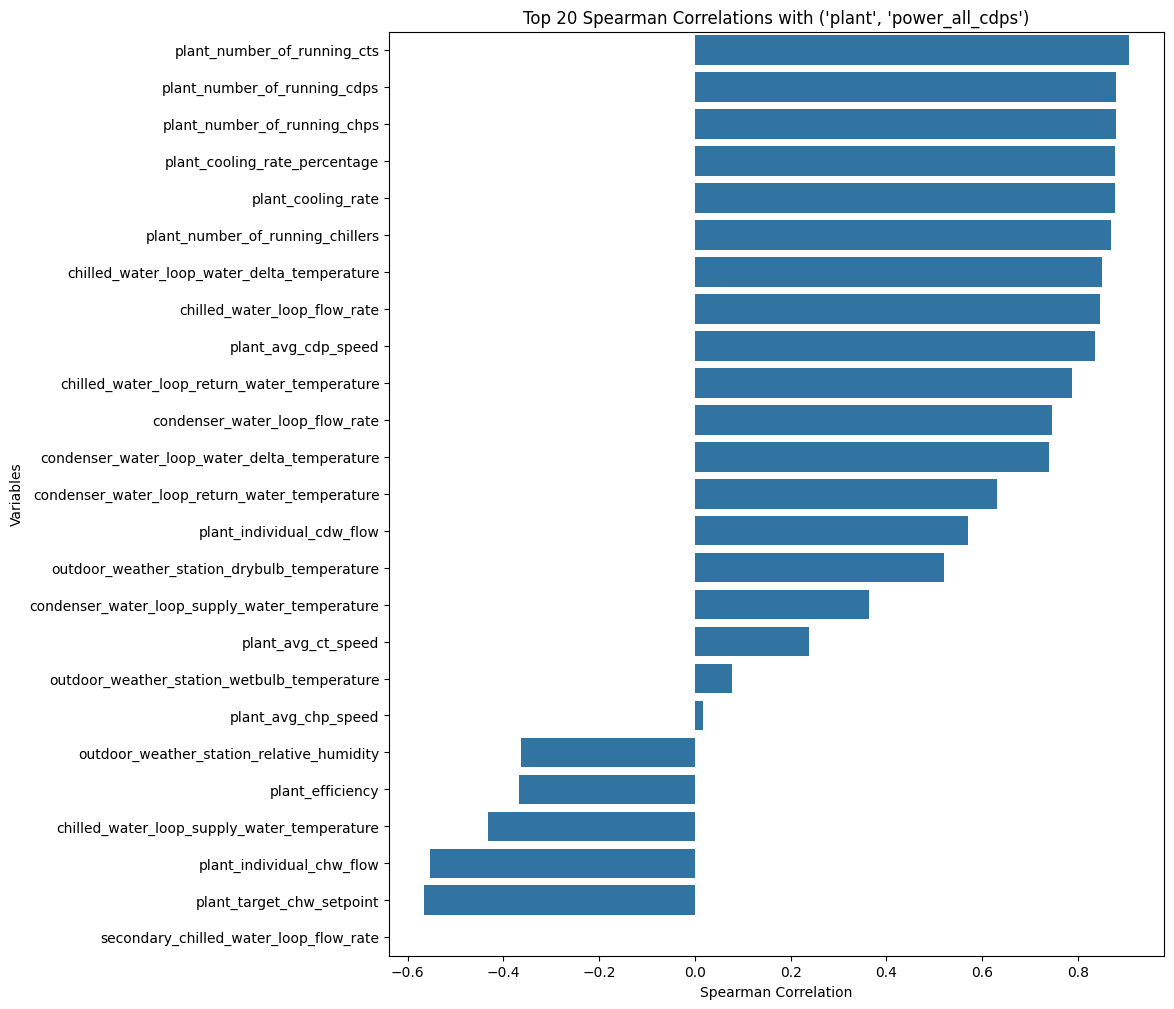

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



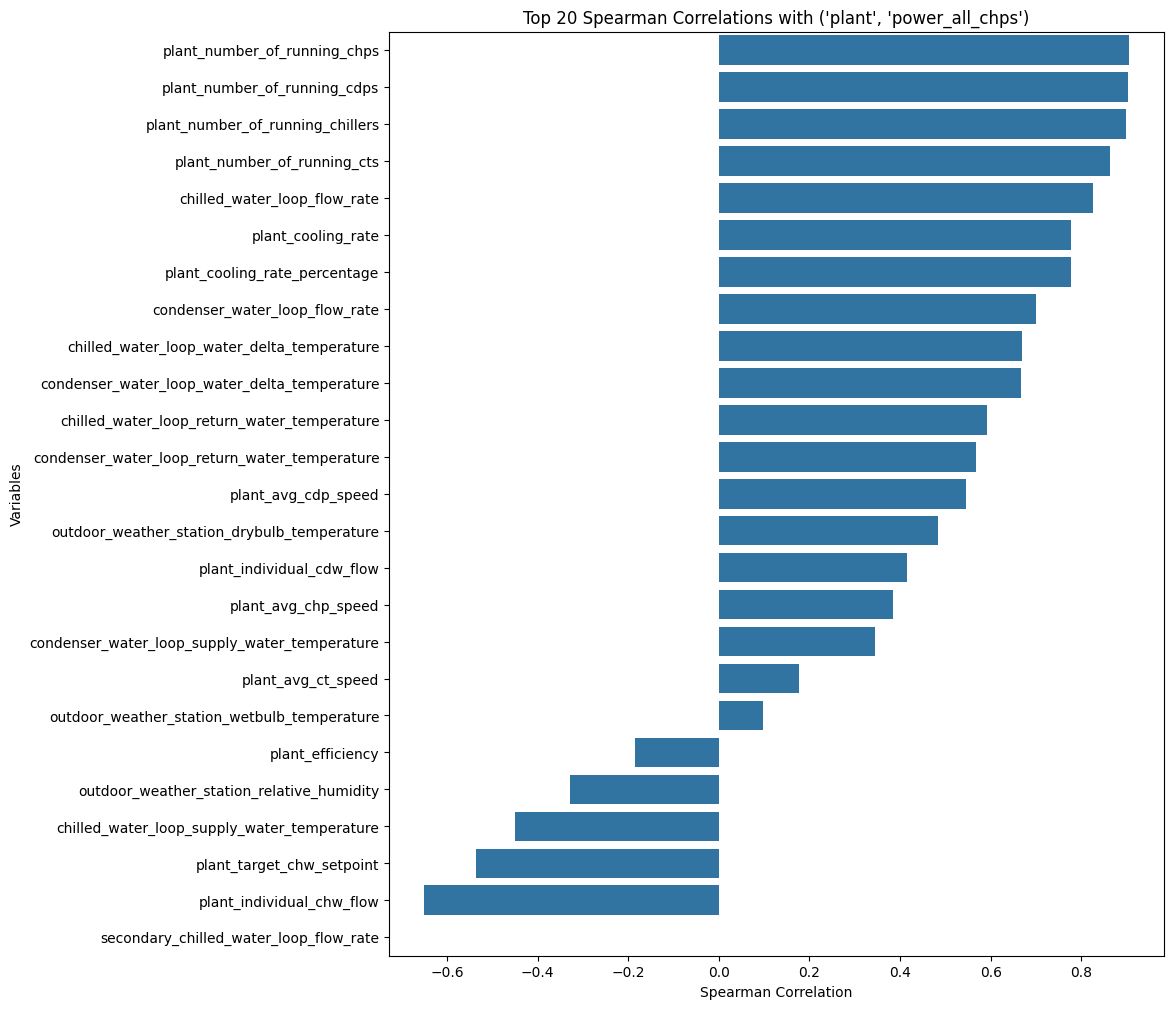

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



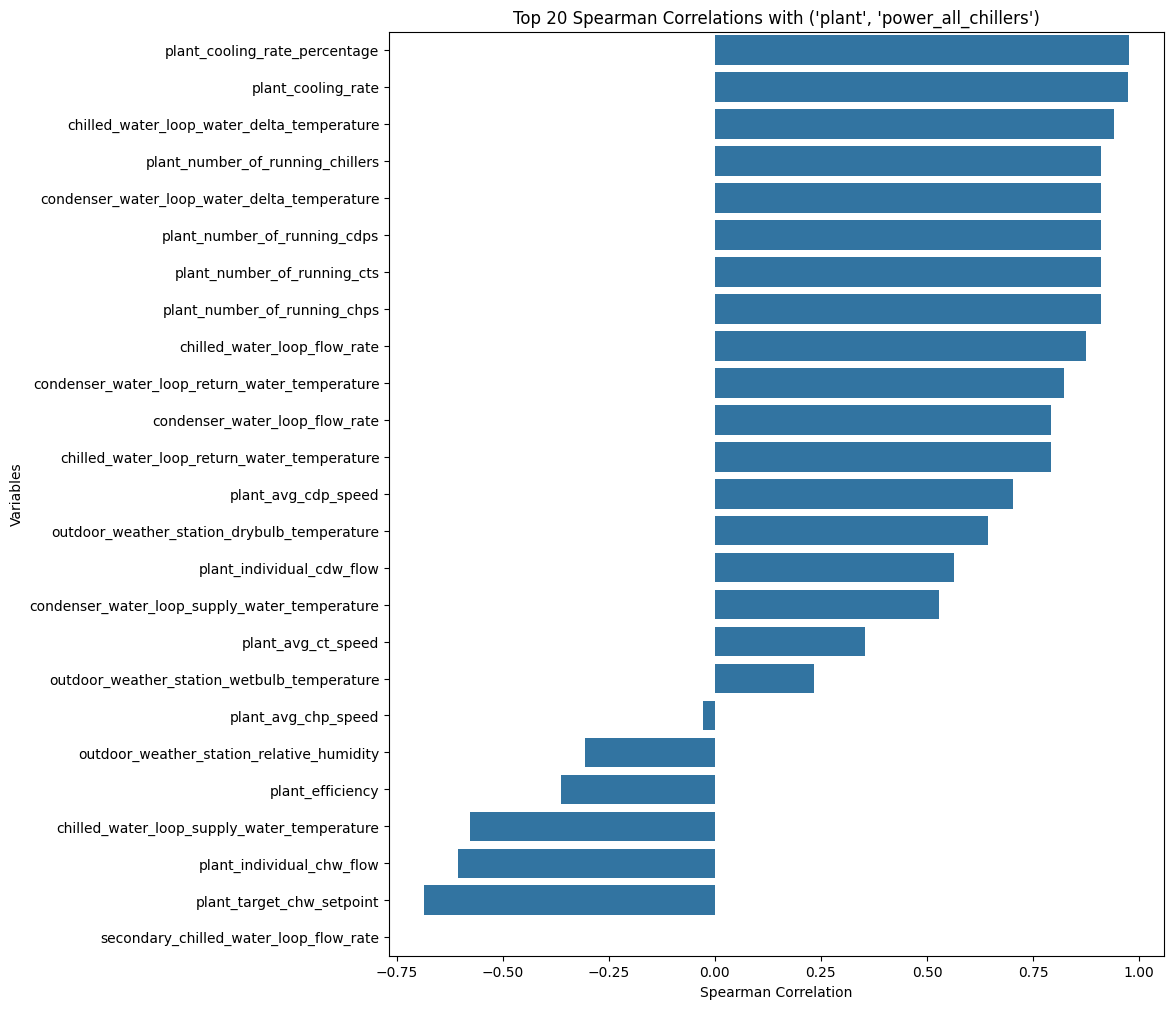

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning:

An input array is constant; the correlation coefficient is not defined.



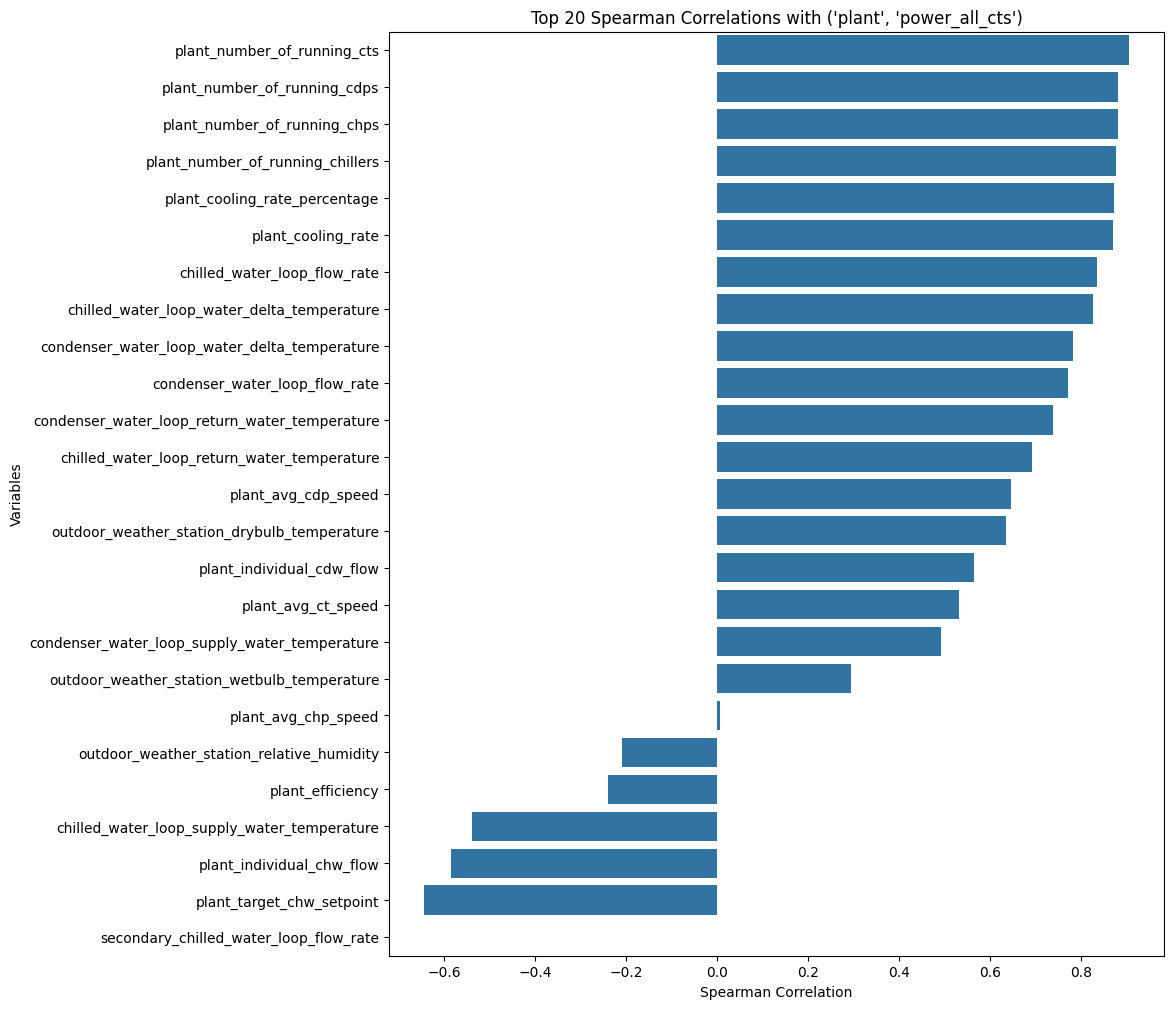

In [51]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Define the list of power columns
power_columns = [col for col in chiller_data.columns if 'plant' in col[0] and 'power' in col[1]]

is_device = ['chiller', 'cdp', 'chp', 'ct']
drop_properties = ['status_read', 'mode', 'current', 'setpoint_read']

# Calculate and plot top 20 Spearman correlations for each power column
for power_col in power_columns:
    compare_columns = [ccol for ccol in chiller_data.columns if (ccol[0] == power_col[0] or ccol[0].split('_')[0] not in is_device)
                       and 'power' not in ccol[1]]
    compare_columns = [ccol for ccol in compare_columns if ccol[1] not in drop_properties]
    
    X = chiller_data[compare_columns]
    y = chiller_data[power_col]
    
    # Calculate Spearman correlation
    correlations = X.apply(lambda col: col.corr(y, method='spearman'))
    corr_series = correlations.sort_values(ascending=False)
    corr_series.index = ['_'.join(col) if isinstance(col, tuple) else col for col in corr_series.index]
    
    plt.figure(figsize=(10, 12))
    sns.barplot(x=corr_series.values, y=corr_series.index)
    plt.title(f'Top 20 Spearman Correlations with {power_col}')
    plt.xlabel('Spearman Correlation')
    plt.ylabel('Variables')
    plt.show()

#### Mutual Info Plant

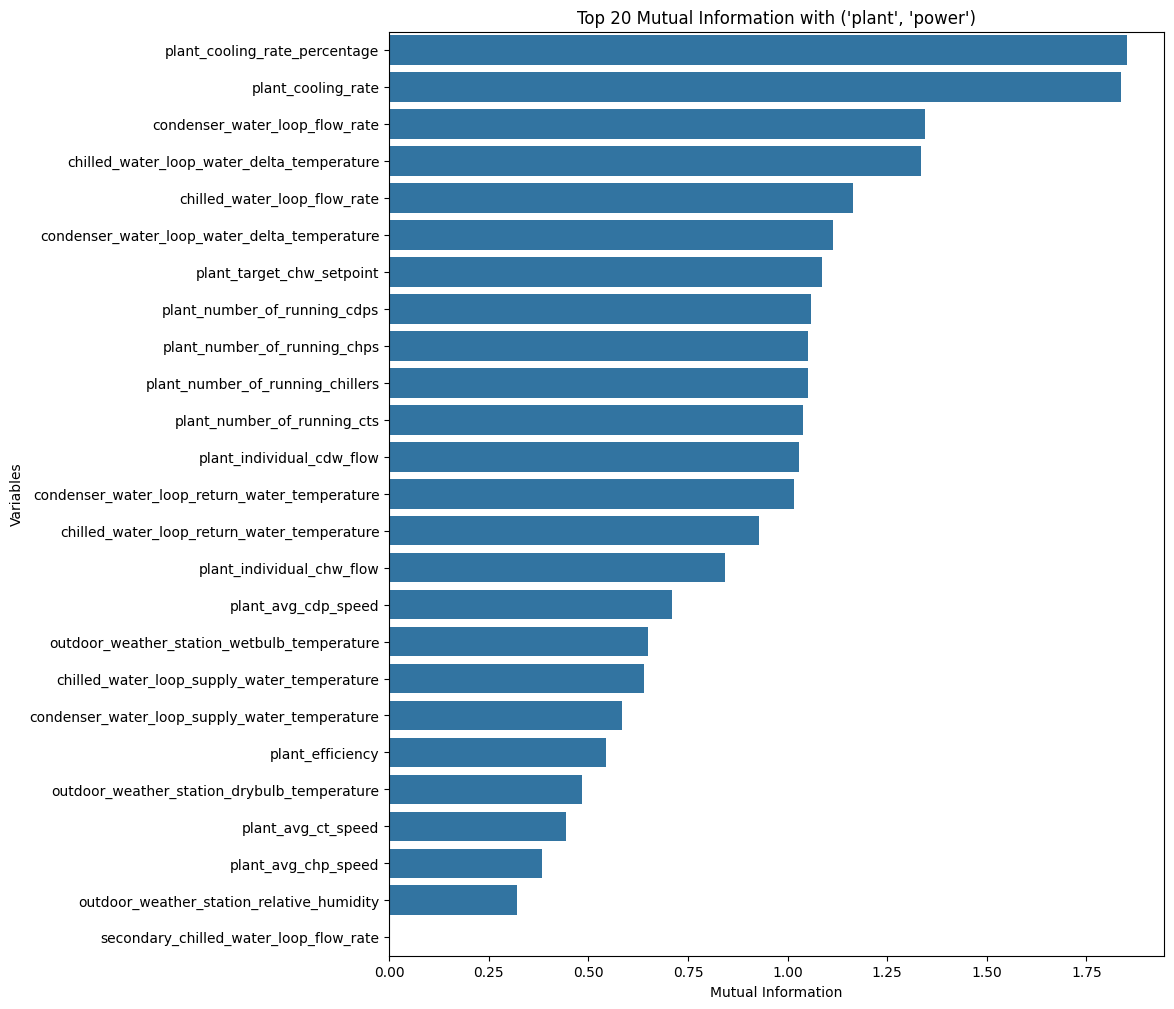

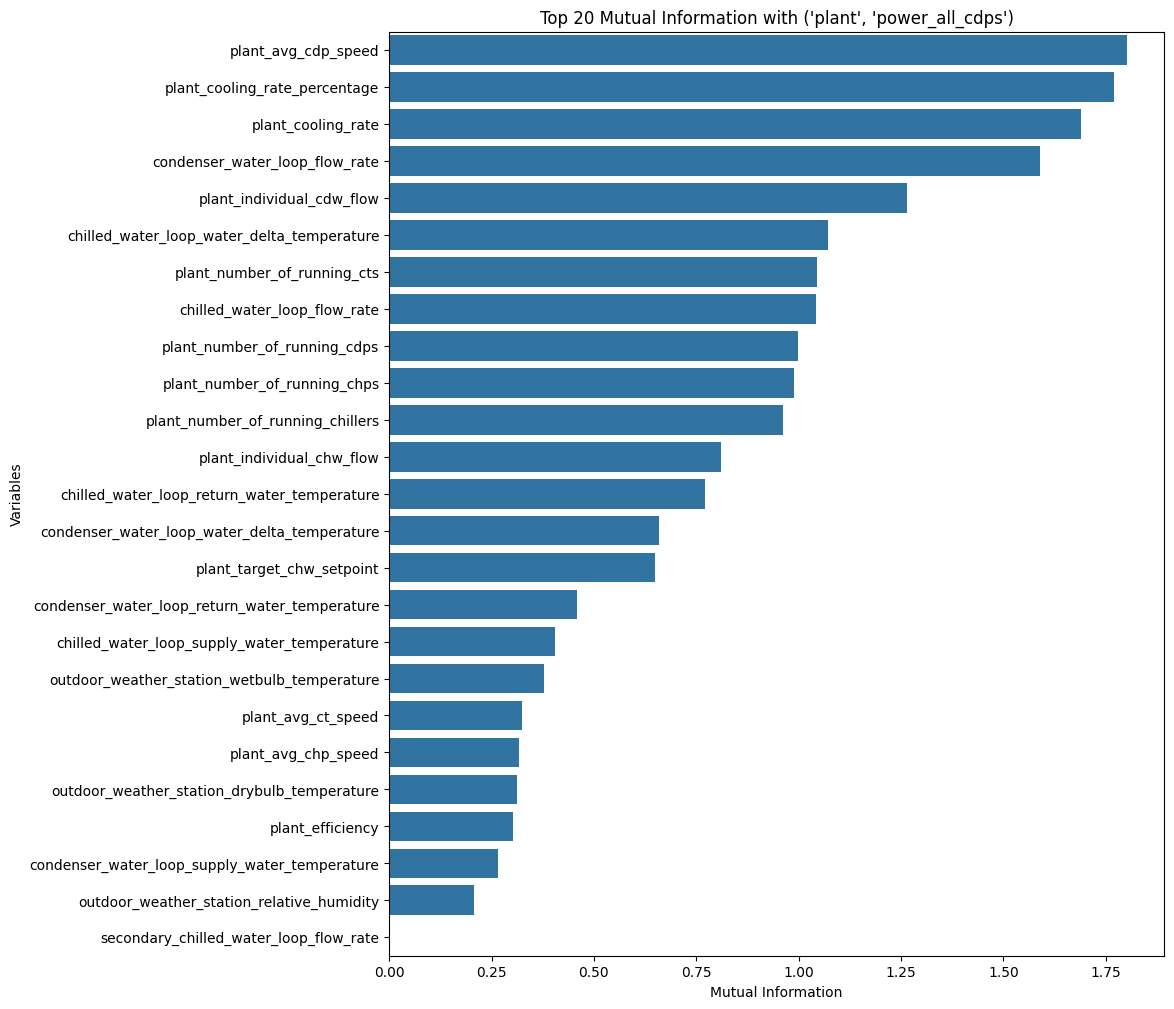

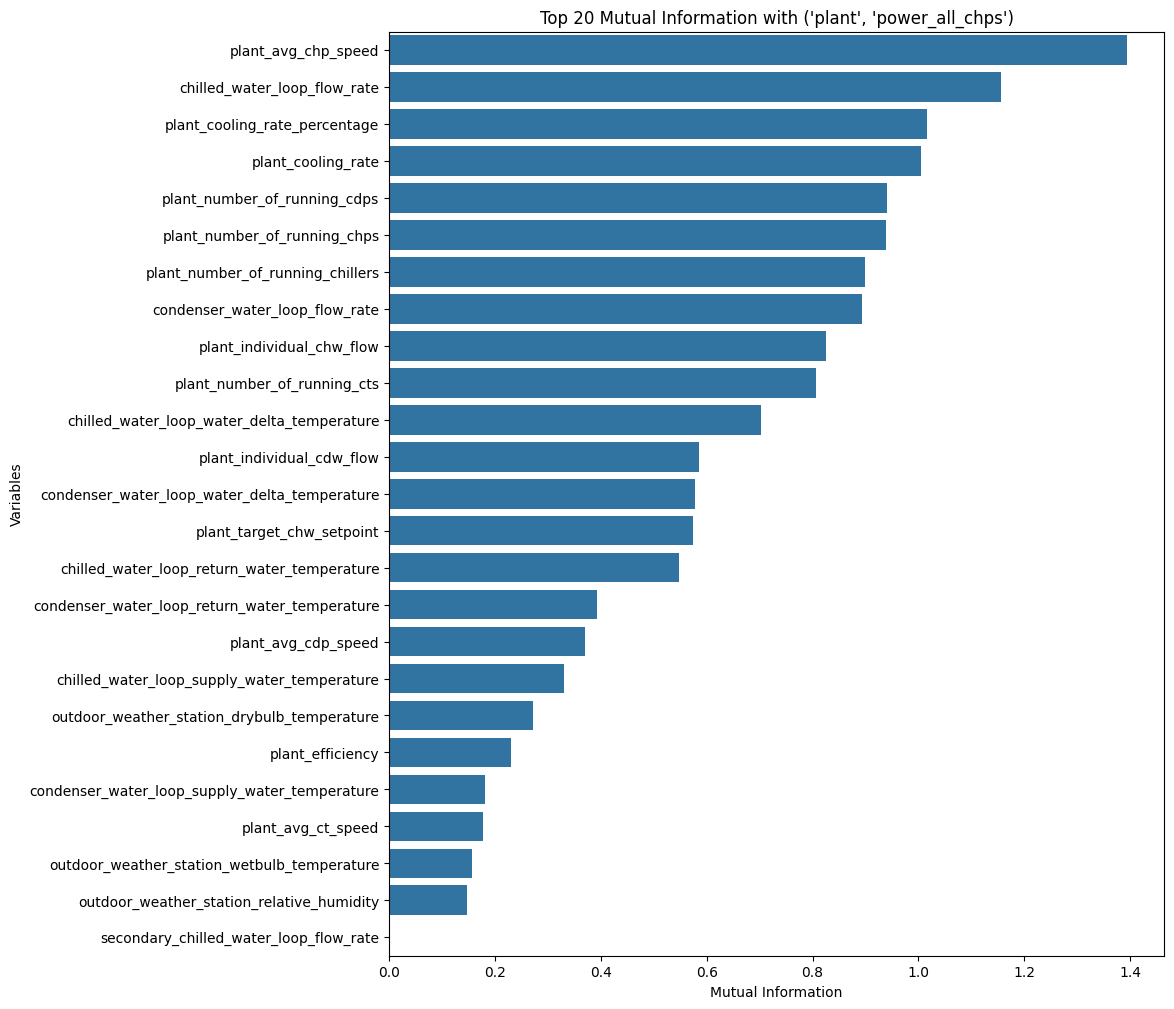

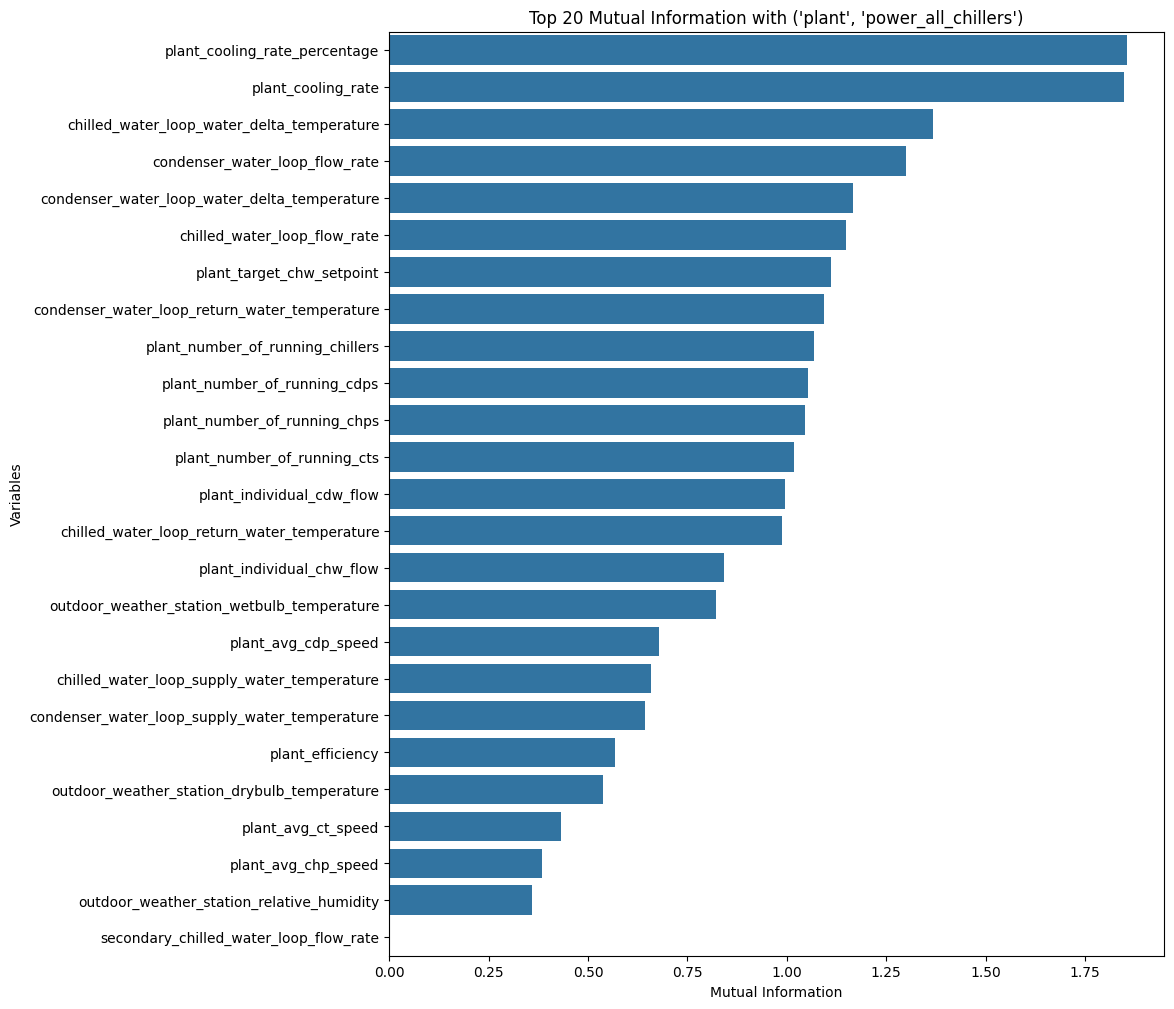

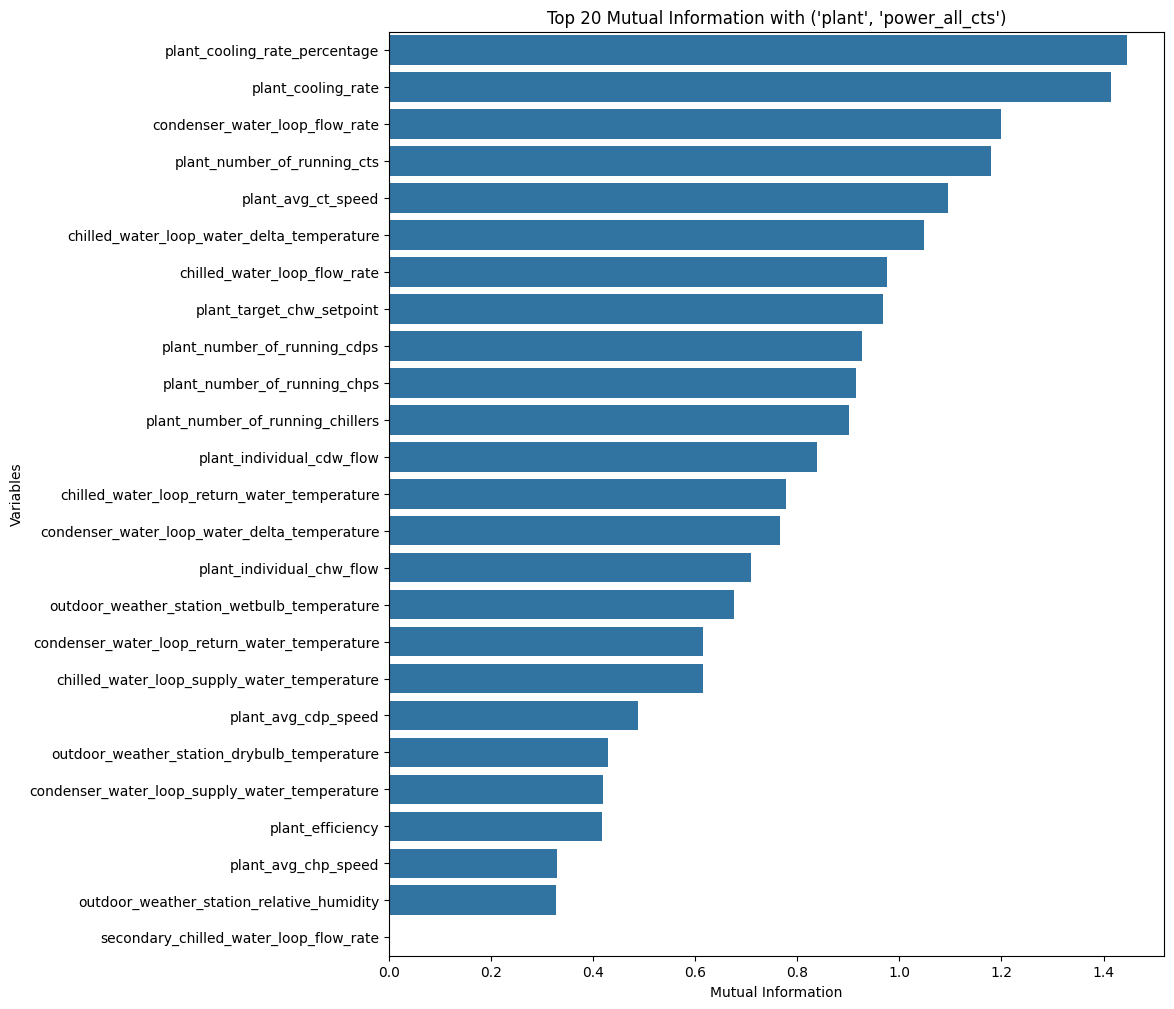

In [52]:
from sklearn.feature_selection import mutual_info_regression
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Define the list of power columns
power_columns = [col for col in chiller_data.columns if 'plant' in col[0] and 'power' in col[1]]

is_device = ['chiller', 'cdp', 'chp', 'ct']
drop_properties = ['status_read', 'mode', 'current', 'setpoint_read']

# Calculate and plot top 20 Spearman correlations for each power column
for power_col in power_columns:
    compare_columns = [ccol for ccol in chiller_data.columns if (ccol[0] == power_col[0] or ccol[0].split('_')[0] not in is_device)
                       and 'power' not in ccol[1]]
    compare_columns = [ccol for ccol in compare_columns if ccol[1] not in drop_properties]
    
    X = chiller_data[compare_columns]
    y = chiller_data[power_col]
    
    mi = mutual_info_regression(X, y)
    mi_series = pd.Series(mi, index=X.columns).sort_values(ascending=False)
    mi_series.index = ['_'.join(col) if isinstance(col, tuple) else col for col in mi_series.index]
    
    plt.figure(figsize=(10, 12))
    sns.barplot(x=mi_series.values, y=mi_series.index)
    plt.title(f'Top 20 Mutual Information with {power_col}')
    plt.xlabel('Mutual Information')
    plt.ylabel('Variables')
    plt.show()

## Feature Engineering

select proper feature from EDA

#### Drop unneccesary columns

For chilller:

    Target: power

    Feature to keep

        cooling_rate ?

        cond_leaving_water_temperature

        cond_entering_water_temperature

        evap_leaving_water_temperature

        evap_entering_water_temperature

        cond_water_flow_rate

        evap_water_flow_rate


In [53]:
chiller_data.describe()

cdp_1                                      cdp_2                \
      frequency_read         power   status_read frequency_read         power   
count   77014.000000  77014.000000  77014.000000   77014.000000  77014.000000   
mean       25.347825      7.097441      0.373542      28.986566      7.809624   
std        33.297336     10.669887      0.483747      33.762993     10.400808   
min         0.000000      0.000000      0.000000       0.000000      0.000000   
25%         0.000000      0.000000      0.000000       0.000000      0.000000   
50%         0.000000      0.000000      0.000000       0.000000      0.000000   
75%        60.400000     12.800000      1.000000      63.000000     14.100000   
max        95.000000     52.900000      1.000000      95.200000     52.700000   

                             cdp_3                                      cdp_4  \
        status_read frequency_read         power   status_read frequency_read   
count  77014.000000   77014.000000  77014.000000  77014.000000   77014.000000   
mean       0.431168      26.288353      7.192194      0.390526      29.070216   
std        0.495243      33.262459     10.334014      0.487872      34.136692   
min        0.000000       0.000000      0.000000      0.000000       0.000000   
25%        0.000000       0.000000      0.000000      0.000000       0.000000   
50%        0.000000       0.000000      0.000000      0.000000       0.000000   
75%        1.000000      61.600000     13.400000      1.000000      63.400000   
max        1.000000      95.200000     52.800000      1.000000     100.000000   

       ...            chiller_3     chiller_4                       \
       ... cond_water_flow_rate  cooling_rate evap_water_flow_rate   
count  ...         77014.000000  77014.000000         77014.000000   
mean   ...           668.594790    245.603010           654.873181   
std    ...           885.847842    296.263317           736.443394   
min    ...             0.000000     -0.000000             0.000000   
25%    ...             0.000000      0.000000             0.000000   
50%    ...             0.000000      0.000000             0.000000   
75%    ...          1550.000000    553.575000          1366.875000   
max    ...          6200.000000   2530.800000          4560.000000   

                               chiller_5                       \
      cond_water_flow_rate  cooling_rate evap_water_flow_rate   
count         77014.000000  77014.000000         77014.000000   
mean            731.953059    181.204504           444.418199   
std             905.098735    280.889545           663.744685   
min               0.000000     -0.000000             0.000000   
25%               0.000000      0.000000             0.000000   
50%               0.000000     -0.000000             0.000000   
75%            1590.000000    492.000000          1210.000000   
max            6280.000000   2985.000000          4610.000000   

                           outdoor_weather_station      chilled_water_loop  \
      cond_water_flow_rate     wetbulb_temperature water_delta_temperature   
count         77014.000000            77014.000000            77014.000000   
mean            515.849050               75.739543                7.216618   
std             836.023921                4.305052                3.330524   
min               0.000000               56.806529                0.000000   
25%               0.000000               75.078903                3.960000   
50%               0.000000               76.953245                7.200000   
75%            1500.000000               78.424100               10.440000   
max            7200.000000               83.981303               15.840000   

         condenser_water_loop  
      water_delta_temperature  
count            77014.000000  
mean                 7.184018  
std                  2.404477  
min                  0.000000  
25%                  4.860000  
50%                  7.920000  
75% 

## System Identification

In [54]:
chiller_data_fit = chiller_data.copy()
chiller_data_fit.columns = ['_'.join(col) if isinstance(col, tuple) else col for col in chiller_data_fit.columns]

#### Chiller_1

##### Linear Regression

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ch1_feature = [col for col in chiller_data_fit.columns if 'chiller_1' in col]

ch1_feature = ['chiller_1_evap_leaving_water_temperature',
               'chiller_1_evap_entering_water_temperature',
               'chiller_1_cond_leaving_water_temperature',
               'chiller_1_cond_entering_water_temperature',
               'chiller_1_evap_water_flow_rate',
               'chiller_1_cond_water_flow_rate']

ch1_target = ['chiller_1_power']

X = chiller_data_fit[ch1_feature]
y = chiller_data_fit[ch1_target]

X_train, y_train = X[:int(0.6*len(X))], y[:int(0.6*len(y))]
X_test, y_test = X[int(0.6*len(X)):], y[int(0.6*len(y)):]

# Train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test)

# Performance
mse_lr = mean_squared_error(y_test, y_pred_lr)
print(f"Linear Regression MSE: {mse_lr}")

Linear Regression MSE: 895.0976819625769


In [56]:
y_pred_lr_df = pd.DataFrame(y_pred_lr, index=y_test.index, columns=y_test.columns)

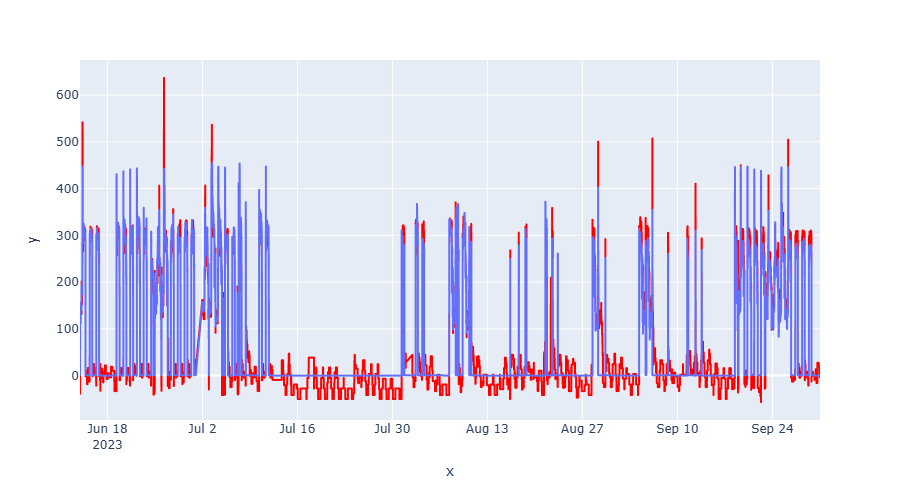

In [57]:
fig = px.line(x=X_test.index, y=y_pred_lr_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])
fig.show()

##### Clipped Ridge Regression

In [58]:
from sklearn.linear_model import Ridge
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ch1_feature = [col for col in chiller_data_fit.columns if 'chiller_1' in col]

ch1_feature = ['chiller_1_evap_leaving_water_temperature',
               'chiller_1_evap_entering_water_temperature',
               'chiller_1_cond_leaving_water_temperature',
               'chiller_1_cond_entering_water_temperature',
               'chiller_1_evap_water_flow_rate',
               'chiller_1_cond_water_flow_rate']

ch1_target = ['chiller_1_power']

X = chiller_data_fit[ch1_feature]
y = chiller_data_fit[ch1_target]

X_train, y_train = X[:int(0.6*len(X))], y[:int(0.6*len(y))]
X_test, y_test = X[int(0.6*len(X)):], y[int(0.6*len(y)):]

# Train the model
ridge_model = Ridge(alpha=1)
ridge_model.fit(X_train, y_train)

# Predict
y_pred_ridge = ridge_model.predict(X_test)

# Performance
mse_lr = mean_squared_error(y_test, y_pred_ridge)
print(f"Linear Regression MSE: {mse_lr}")

y_pred_ridge_clipped = y_pred_ridge.clip(min=0)
# Performance after clipping
mse_ridge_clipped = mean_squared_error(y_test, y_pred_ridge_clipped)
print(f"Ridge Regression MSE after Clipping: {mse_ridge_clipped}")

Linear Regression MSE: 895.097878660791
Ridge Regression MSE after Clipping: 611.7170224554071


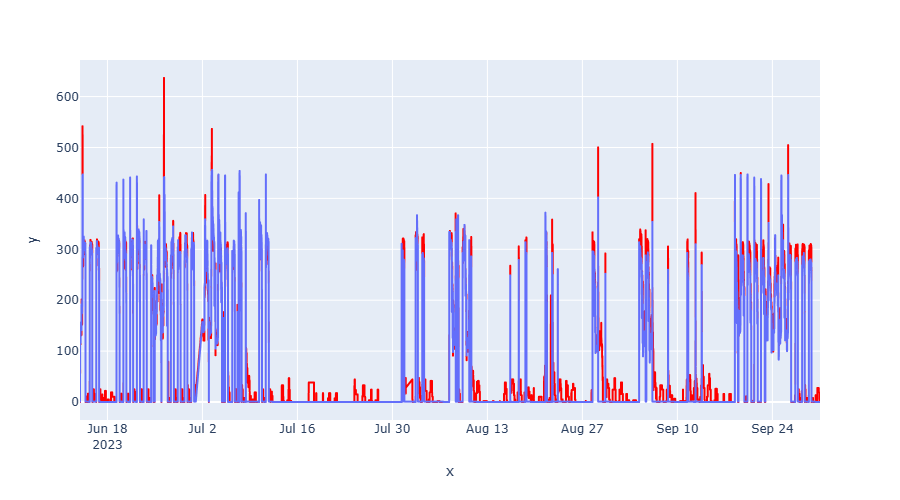

In [59]:
y_pred_ridge_df = pd.DataFrame(y_pred_ridge, index=y_test.index, columns=y_test.columns)
y_pred_ridge_clipped_df = pd.DataFrame(y_pred_ridge_clipped, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_ridge_clipped_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])
fig.show()

##### Random Forest Regression

In [60]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

ch1_feature = ['chiller_1_evap_leaving_water_temperature',
               'chiller_1_evap_entering_water_temperature',
               'chiller_1_cond_leaving_water_temperature',
               'chiller_1_cond_entering_water_temperature',
               'chiller_1_evap_water_flow_rate',
               'chiller_1_cond_water_flow_rate']

ch1_target = ['chiller_1_power']

X = chiller_data_fit[ch1_feature]
y = chiller_data_fit[ch1_target]

X_train, y_train = X[:int(0.6*len(X))], y[:int(0.6*len(y))]
X_test, y_test = X[int(0.6*len(X)):], y[int(0.6*len(y)):]
# Random Forest Model
rf_model = RandomForestRegressor(n_estimators=400,
                           max_depth=30,
                           min_samples_split=10,
                           min_samples_leaf=6, 
                           random_state=42, 
                           bootstrap=True)
rf_model.fit(X_train, y_train.values.ravel())

y_pred_rf = rf_model.predict(X_test)

mse_rf = mean_squared_error(y_test, y_pred_rf)
print(f"Random Forest MSE: {mse_rf}")

# Clipping negative predictions to zero
y_pred_rf_clipped = y_pred_rf.clip(min=0)

# Performance after clipping
mse_rf_clipped = mean_squared_error(y_test, y_pred_rf_clipped)
print(f"Random Forest MSE after Clipping: {mse_rf_clipped}")

Random Forest MSE: 348.3858130991401
Random Forest MSE after Clipping: 348.3858130991401


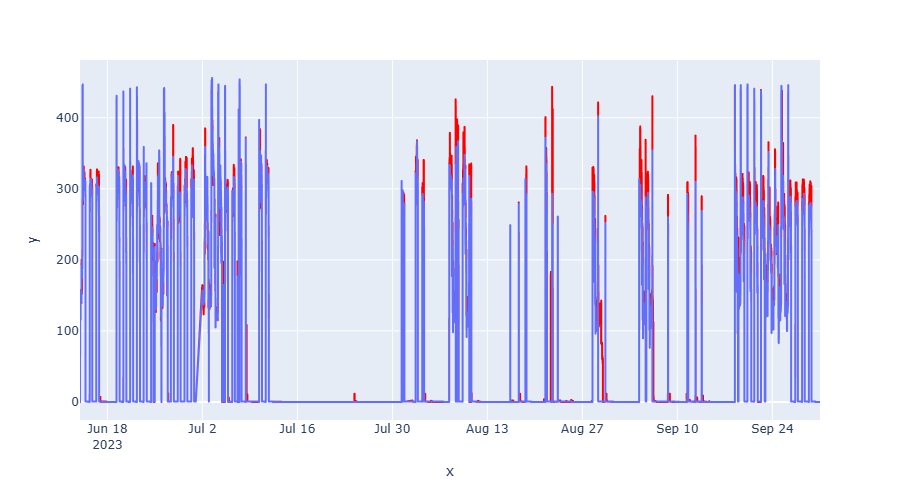

In [61]:
y_pred_rf_clipped_df = pd.DataFrame(y_pred_rf_clipped, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_rf_clipped_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])

##### Grid Search Random Forest

In [62]:
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'min_samples_split': [3, 5, 10, 12],
    'min_samples_leaf': [2, 4, 6, 10],
}

# Create a base model
rf = RandomForestRegressor(n_estimators=400,
                           max_depth=30, 
                           random_state=42, 
                           bootstrap=True)

# Instantiate the grid search model
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, 
                          cv=3, n_jobs=-1, verbose=2, scoring='neg_mean_squared_error')

# Fit the grid search to the data
grid_search.fit(X_train, y_train.values.ravel())

# Print the best parameters and the best score
print(f"Best Parameters: {grid_search.best_params_}")
print(f"Best Score: {grid_search.best_score_}")

# Use the best model
best_rf_model = grid_search.best_estimator_

# Predict
y_pred_best_rf = best_rf_model.predict(X_test)

# Performance
mse_best_rf = mean_squared_error(y_test, y_pred_best_rf)
print(f"Random Forest MSE (Best Model): {mse_best_rf}")

# Clipping negative predictions to zero
y_pred_best_rf_clipped = y_pred_best_rf.clip(min=0)

# Performance after clipping
mse_best_rf_clipped = mean_squared_error(y_test, y_pred_best_rf_clipped)
print(f"Random Forest MSE after Clipping (Best Model): {mse_best_rf_clipped}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters: {'min_samples_leaf': 6, 'min_samples_split': 3}
Best Score: -408.90065476011563
Random Forest MSE (Best Model): 348.3858130991401
Random Forest MSE after Clipping (Best Model): 348.3858130991401


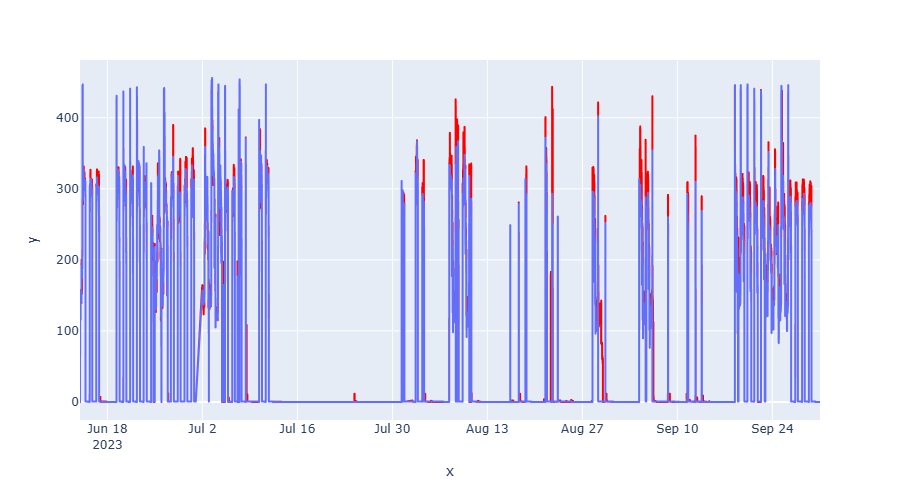

In [63]:
y_pred_best_rf_clipped_df = pd.DataFrame(y_pred_best_rf_clipped, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=y_pred_best_rf_clipped_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])

##### ARIMA Regression with predictor variables

##### SARIMAX Regression

In [64]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error
import numpy as np

ch1_feature = [
    'chiller_1_evap_leaving_water_temperature',
    'chiller_1_evap_entering_water_temperature',
    'chiller_1_cond_leaving_water_temperature',
    'chiller_1_cond_entering_water_temperature',
    'chiller_1_evap_water_flow_rate',
    'chiller_1_cond_water_flow_rate'
]

ch1_target = ['chiller_1_power']

X = chiller_data_fit[ch1_feature]
y = chiller_data_fit[ch1_target]

# Ensure the index has a datetime frequency
X.index = pd.to_datetime(X.index)
y.index = pd.to_datetime(y.index)
X.index.freq = pd.infer_freq(X.index)
y.index.freq = pd.infer_freq(y.index)

# Splitting the data into train and test sets
train_size = int(0.6 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

# Define the SARIMAX model
model = SARIMAX(endog=y_train, exog=X_train, order=(2, 1, 3), seasonal_order=(0,0,0,0))

# Fit the SARIMAX model
fitted_model = model.fit()

# Print the coefficients
print("Coefficients of the SARIMAX model:")
print(fitted_model.params)

# Print the summary of the fitted model
print(fitted_model.summary())


# Forecast using the SARIMAX model
forecast = fitted_model.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
#forecast = np.maximum(forecast, 0)

# Calculate MSE
mse_sarimax = mean_squared_error(y_test, forecast)
print(f"SARIMAX MSE: {mse_sarimax}")

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



Coefficients of the SARIMAX model:
chiller_1_evap_leaving_water_temperature     -14.393066
chiller_1_evap_entering_water_temperature      9.327154
chiller_1_cond_leaving_water_temperature       6.215054
chiller_1_cond_entering_water_temperature     -2.125823
chiller_1_evap_water_flow_rate                 0.010307
chiller_1_cond_water_flow_rate                 0.011821
ar.L1                                          0.508361
ar.L2                                          0.408753
ma.L1                                         -0.678945
ma.L2                                         -0.366765
ma.L3                                          0.059021
sigma2                                       118.583076
dtype: float64
                               SARIMAX Results                                
Dep. Variable:        chiller_1_power   No. Observations:                46208
Model:               SARIMAX(2, 1, 3)   Log Likelihood             -176016.904
Date:                Thu, 22 Oct 2026   A

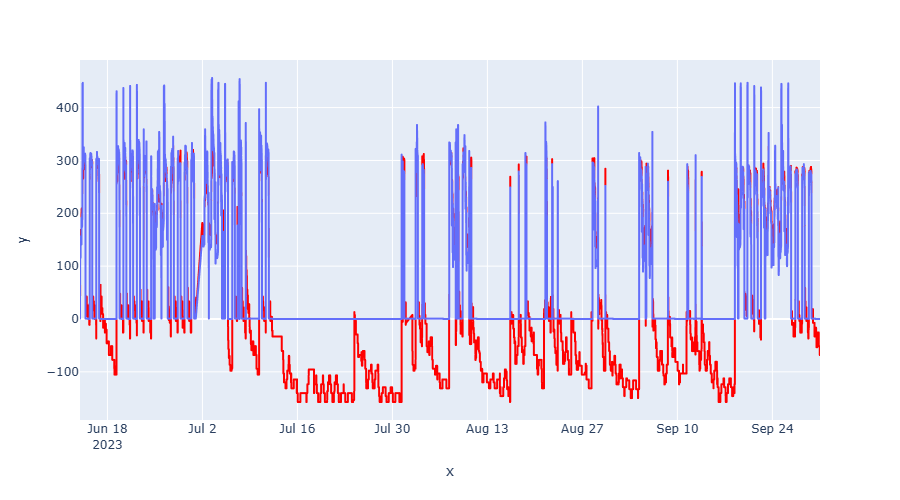

In [65]:
forecast_df = pd.DataFrame(forecast.values, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=forecast_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])

##### SARIMAX with log

In [66]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error
import numpy as np

# Define features and target
ch1_feature = [
    'chiller_1_evap_leaving_water_temperature',
    'chiller_1_evap_entering_water_temperature',
    'chiller_1_cond_leaving_water_temperature',
    'chiller_1_cond_entering_water_temperature',
    'chiller_1_evap_water_flow_rate',
    'chiller_1_cond_water_flow_rate'
]

ch1_target = ['chiller_1_power']

X = chiller_data_fit[ch1_feature]
y = chiller_data_fit[ch1_target]

# Apply log transformation to the target variable to ensure non-negative predictions
y_log = np.log1p(y)  # log1p is used to avoid log(0) issues

# Splitting the data into train and test sets
train_size = int(0.6 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train_log, y_test_log = y_log[:train_size], y_log[train_size:]

# Define the SARIMAX model
model = SARIMAX(endog=y_train_log, exog=X_train, order=(1, 1, 1), seasonal_order=(0, 0, 0, 0))

# Fit the SARIMAX model
fitted_model = model.fit()

# Forecast using the SARIMAX model
forecast_log = fitted_model.forecast(steps=len(X_test), exog=X_test, index=X_test.index)

# Transform the predictions back to the original scale
forecast = np.expm1(forecast_log)  # expm1 is the inverse of log1p

# Calculate MSE
mse_sarimax = mean_squared_error(y_test, forecast)
print(f"SARIMAX MSE: {mse_sarimax}")

# Ensure predictions are non-negative
# forecast = np.maximum(forecast, 0)
mse_sarimax_clipped = mean_squared_error(y_test, forecast)
print(f"SARIMAX MSE after clipping: {mse_sarimax_clipped}")

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning:

Maximum Likelihood optimization failed to converge. Check mle_retvals



SARIMAX MSE: 6914.694758501726
SARIMAX MSE after clipping: 6914.694758501726


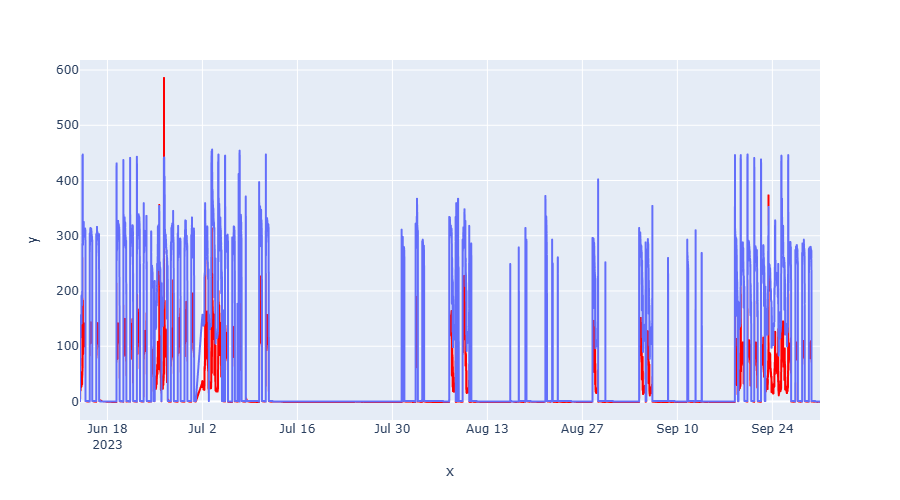

In [67]:
forecast_df = pd.DataFrame(forecast.values, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=forecast_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])

##### SARIMAX feature engineering

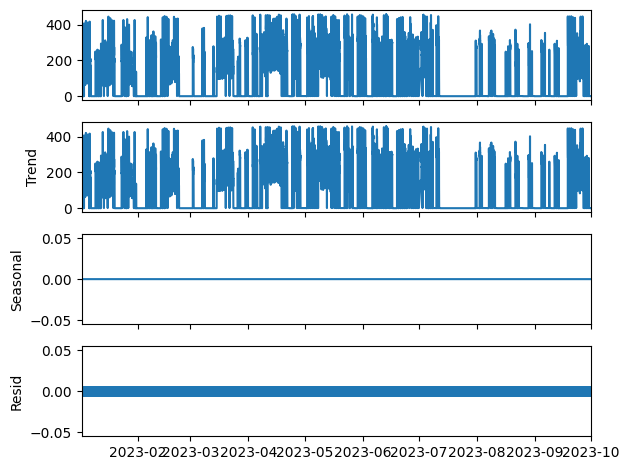

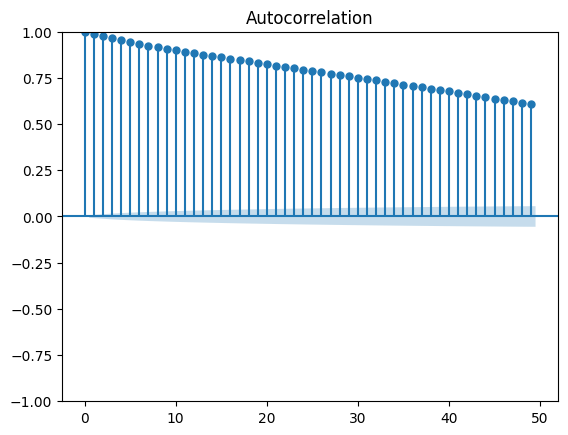

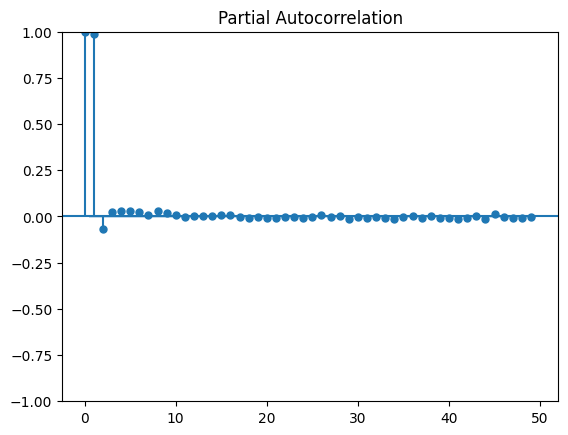

In [68]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error
import numpy as np

ch1_feature = [
    'chiller_1_evap_leaving_water_temperature',
    'chiller_1_evap_entering_water_temperature',
    'chiller_1_cond_leaving_water_temperature',
    'chiller_1_cond_entering_water_temperature',
    'chiller_1_evap_water_flow_rate',
    'chiller_1_cond_water_flow_rate',
    'chiller_1_demand_limit_setpoint_read'
]

ch1_target = ['chiller_1_power']

X = chiller_data_fit[ch1_feature]
y = chiller_data_fit[ch1_target]

# Ensure the index has a datetime frequency
X.index = pd.to_datetime(X.index)
y.index = pd.to_datetime(y.index)
X.index.freq = pd.infer_freq(X.index)
y.index.freq = pd.infer_freq(y.index)

# Splitting the data into train and test sets
train_size = int(0.6 * len(X))
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

decomposition = seasonal_decompose(y, period=1)  # Adjust period based on your data's seasonal cycle
# Plot seasonal components
decomposition.plot()
plt.show()

# ACF and PACF plots
plot_acf(y)
plot_pacf(y)
plt.show()

In [69]:
# Define the SARIMAX model
model = SARIMAX(endog=y_train, exog=X_train, order=(2, 1, 3), seasonal_order=(0,0,0,0))

# Fit the SARIMAX model
fitted_model = model.fit()

# Print the coefficients
print("Coefficients of the SARIMAX model:")
print(fitted_model.params)

# Print the summary of the fitted model
print(fitted_model.summary())


# Forecast using the SARIMAX model
forecast = fitted_model.forecast(steps=len(X_test), exog=X_test, index=X_test.index)
#forecast = np.maximum(forecast, 0)

# Calculate MSE
mse_sarimax = mean_squared_error(y_test, forecast)
print(f"SARIMAX MSE: {mse_sarimax}")

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\base\tsa_model.py:480: ValueWarning:

A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning:

Non-invertible starting MA parameters found. Using zeros as starting parameters.

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5

Coefficients of the SARIMAX model:
chiller_1_evap_leaving_water_temperature     -12.637039
chiller_1_evap_entering_water_temperature      8.079375
chiller_1_cond_leaving_water_temperature       5.296603
chiller_1_cond_entering_water_temperature     -2.195793
chiller_1_evap_water_flow_rate                 0.007413
chiller_1_cond_water_flow_rate                 0.010135
chiller_1_demand_limit_setpoint_read           0.782516
ar.L1                                          0.032534
ar.L2                                          0.960495
ma.L1                                         -0.142877
ma.L2                                         -0.967963
ma.L3                                          0.111444
sigma2                                       114.830639
dtype: float64
                               SARIMAX Results                                
Dep. Variable:        chiller_1_power   No. Observations:                46208
Model:               SARIMAX(2, 1, 3)   Log Likelihood          

In [70]:
forecast = np.maximum(forecast, 0)

# Calculate MSE
mse_sarimax = mean_squared_error(y_test, forecast)
print(f"SARIMAX MSE: {mse_sarimax}")

SARIMAX MSE: 691.6629572669508


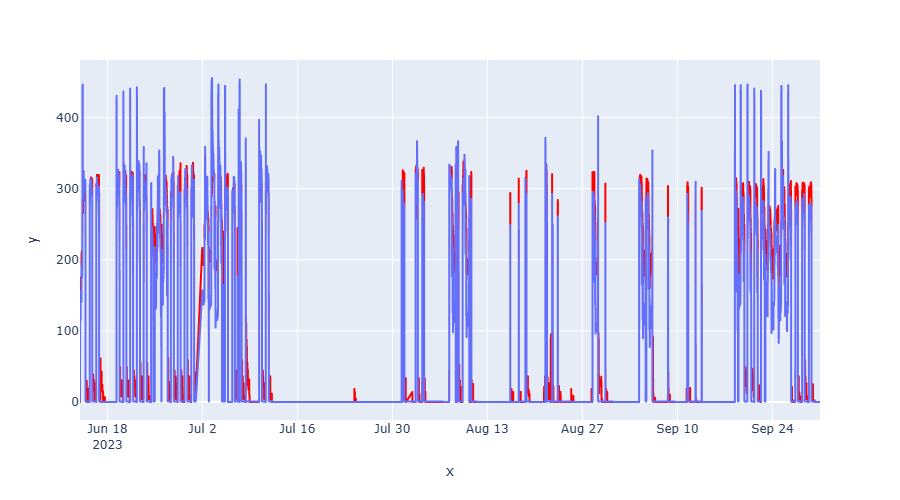

In [71]:
forecast_df = pd.DataFrame(forecast.values, index=y_test.index, columns=y_test.columns)
fig = px.line(x=X_test.index, y=forecast_df['chiller_1_power'])
fig.update_traces(line_color='red', name='Chiller 1 Power')
fig.add_trace(px.line(x=X_test.index, y=y_test['chiller_1_power']).data[0])

## System Identification Plant

##### Random Forest

Random Forest MSE: 2825.3707415074555
Random Forest MSE after Clipping: 2825.3707415074555


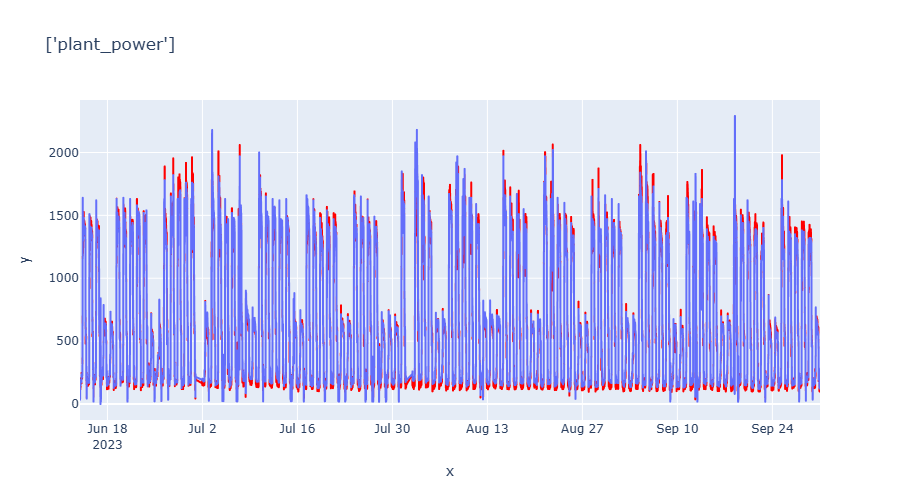

Random Forest MSE: 6.950526175633633
Random Forest MSE after Clipping: 6.950526175633633


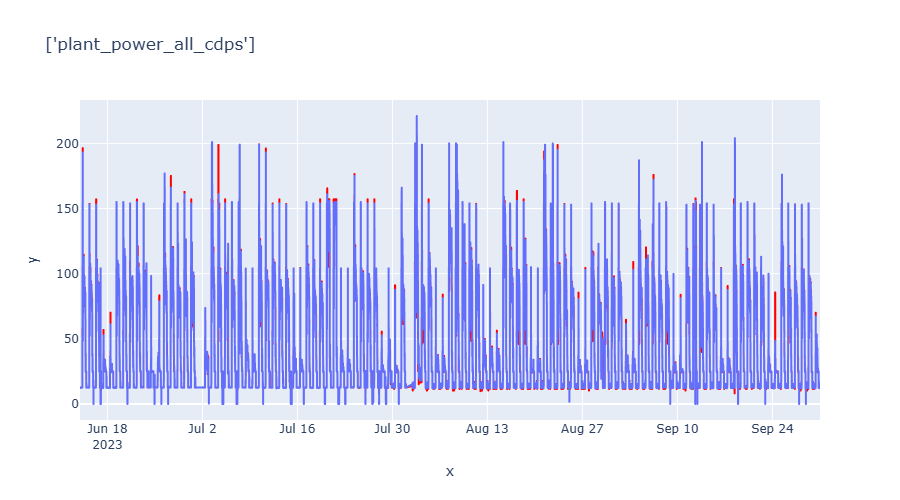

Random Forest MSE: 9.933510920376472
Random Forest MSE after Clipping: 9.933510920376472


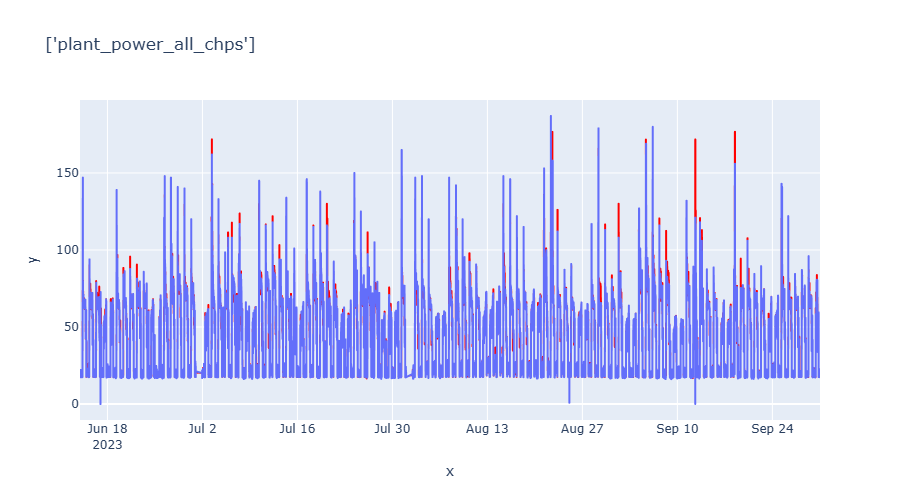

Random Forest MSE: 2739.399316673716
Random Forest MSE after Clipping: 2739.399316673716


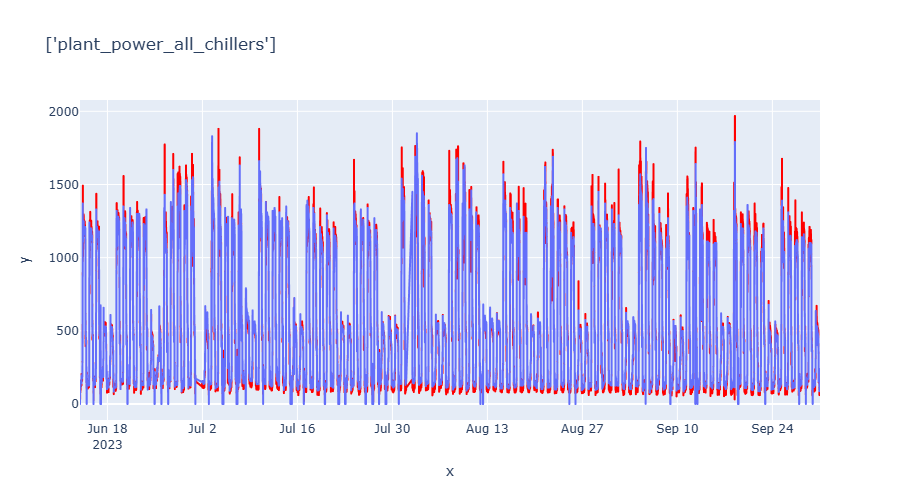

Random Forest MSE: 4.037288528945389
Random Forest MSE after Clipping: 4.037288528945389


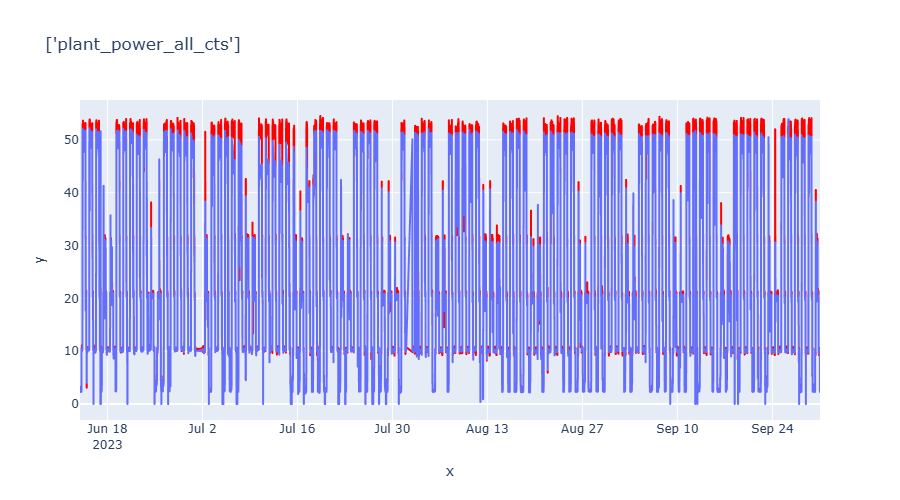

In [72]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

plant_features = {'plant_power':['condenser_water_loop_flow_rate',
                                 'chilled_water_loop_flow_rate',
                                 'condenser_water_loop_water_delta_temperature',
                                 'chilled_water_loop_water_delta_temperature',
                                 'plant_number_of_running_chps'],
                    'plant_power_all_cdps':['plant_avg_cdp_speed',
                                          'condenser_water_loop_flow_rate'],
                    'plant_power_all_chps':['plant_avg_chp_speed',
                                          'chilled_water_loop_flow_rate'],
                    'plant_power_all_chillers':['condenser_water_loop_flow_rate',
                                 'chilled_water_loop_flow_rate',
                                 'condenser_water_loop_water_delta_temperature',
                                 'chilled_water_loop_water_delta_temperature',],
                    'plant_power_all_cts':['condenser_water_loop_flow_rate',
                                           'plant_number_of_running_cts',
                                           'plant_avg_ct_speed',
                                           'condenser_water_loop_water_delta_temperature']}

plant_targets = [[col] for col in chiller_data_fit.columns if 'plant' in col and 'power' in col]

for target in plant_targets:
    X = chiller_data_fit[plant_features[target[0]]]
    y = chiller_data_fit[target]

    X_train, y_train = X[:int(0.6*len(X))], y[:int(0.6*len(y))]
    X_test, y_test = X[int(0.6*len(X)):], y[int(0.6*len(y)):]
    # Random Forest Model
    rf_model = RandomForestRegressor(n_estimators=400,
                           max_depth=30,
                           min_samples_split=10,
                           min_samples_leaf=6, 
                           random_state=42, 
                           bootstrap=True)
    rf_model.fit(X_train, y_train.values.ravel())

    y_pred_rf = rf_model.predict(X_test)

    mse_rf = mean_squared_error(y_test, y_pred_rf)
    print(f"Random Forest MSE: {mse_rf}")

    # Clipping negative predictions to zero
    y_pred_rf_clipped = y_pred_rf.clip(min=0)

    # Performance after clipping
    mse_rf_clipped = mean_squared_error(y_test, y_pred_rf_clipped)
    print(f"Random Forest MSE after Clipping: {mse_rf_clipped}")
    y_pred_rf_clipped_df = pd.DataFrame(y_pred_rf_clipped, index=y_test.index, columns=y_test.columns)
    fig = px.line(x=X_test.index, y=y_pred_rf_clipped_df[target[0]], title=f'{target}')
    fig.update_traces(line_color='red', name=f'{target}')
    fig.add_trace(px.line(x=X_test.index, y=y_test[target[0]]).data[0])
    fig.show()

##### NARX

Using device: cuda
X_train shape: (46206, 24)
X_train_scaled shape before reshape: (46206, 24)
Expected reshape dimensions: (46206, 4, 6)
Epoch [1/10], Loss: 0.8577
Epoch [2/10], Loss: 0.8251
Epoch [3/10], Loss: 0.7927
Epoch [4/10], Loss: 0.7604
Epoch [5/10], Loss: 0.7282
Epoch [6/10], Loss: 0.6961
Epoch [7/10], Loss: 0.6641
Epoch [8/10], Loss: 0.6321
Epoch [9/10], Loss: 0.6000
Epoch [10/10], Loss: 0.5680
NARX MSE for plant_power: 140427.28125
NARX MSE after Clipping for plant_power: 140427.28125


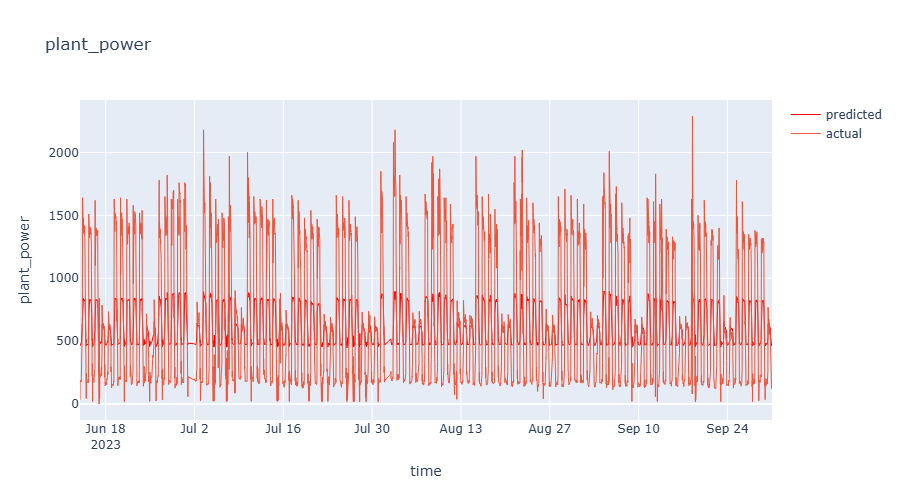

X_train shape: (46206, 12)
X_train_scaled shape before reshape: (46206, 12)
Expected reshape dimensions: (46206, 4, 3)
Epoch [1/10], Loss: 1.0205
Epoch [2/10], Loss: 0.9983
Epoch [3/10], Loss: 0.9764
Epoch [4/10], Loss: 0.9549
Epoch [5/10], Loss: 0.9337
Epoch [6/10], Loss: 0.9128
Epoch [7/10], Loss: 0.8922
Epoch [8/10], Loss: 0.8718
Epoch [9/10], Loss: 0.8515
Epoch [10/10], Loss: 0.8314
NARX MSE for plant_power_all_cdps: 1126.25927734375
NARX MSE after Clipping for plant_power_all_cdps: 1126.25927734375


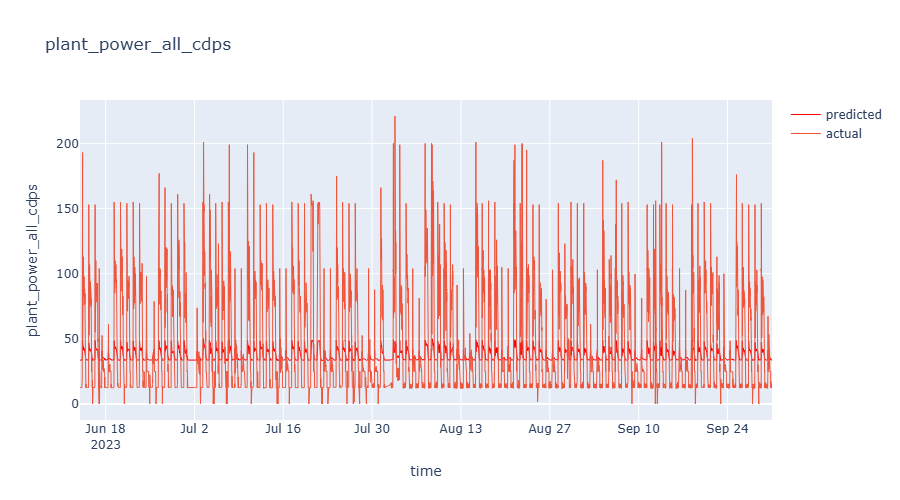

X_train shape: (46206, 12)
X_train_scaled shape before reshape: (46206, 12)
Expected reshape dimensions: (46206, 4, 3)
Epoch [1/10], Loss: 1.0450
Epoch [2/10], Loss: 1.0239
Epoch [3/10], Loss: 1.0032
Epoch [4/10], Loss: 0.9826
Epoch [5/10], Loss: 0.9622
Epoch [6/10], Loss: 0.9418
Epoch [7/10], Loss: 0.9216
Epoch [8/10], Loss: 0.9014
Epoch [9/10], Loss: 0.8813
Epoch [10/10], Loss: 0.8611
NARX MSE for plant_power_all_chps: 478.59326171875
NARX MSE after Clipping for plant_power_all_chps: 478.59326171875


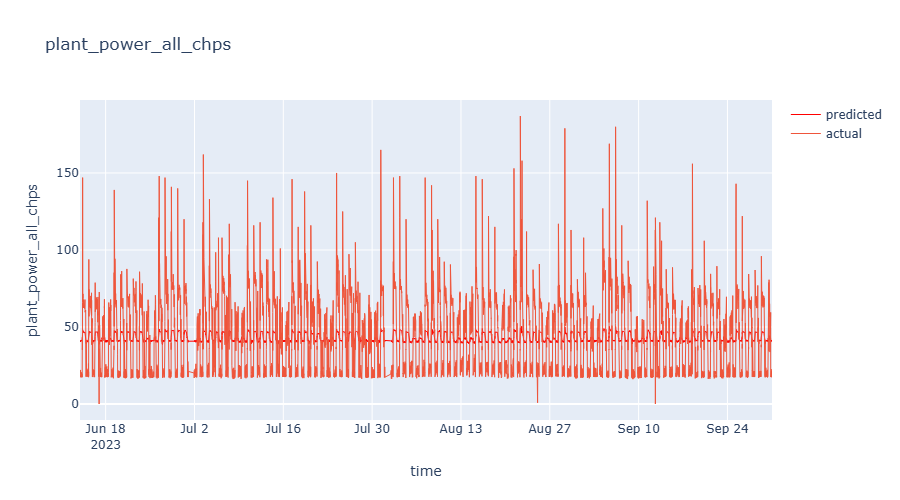

X_train shape: (46206, 20)
X_train_scaled shape before reshape: (46206, 20)
Expected reshape dimensions: (46206, 4, 5)
Epoch [1/10], Loss: 0.9938
Epoch [2/10], Loss: 0.9624
Epoch [3/10], Loss: 0.9318
Epoch [4/10], Loss: 0.9018
Epoch [5/10], Loss: 0.8724
Epoch [6/10], Loss: 0.8436
Epoch [7/10], Loss: 0.8153
Epoch [8/10], Loss: 0.7873
Epoch [9/10], Loss: 0.7596
Epoch [10/10], Loss: 0.7322
NARX MSE for plant_power_all_chillers: 139080.578125
NARX MSE after Clipping for plant_power_all_chillers: 139080.578125


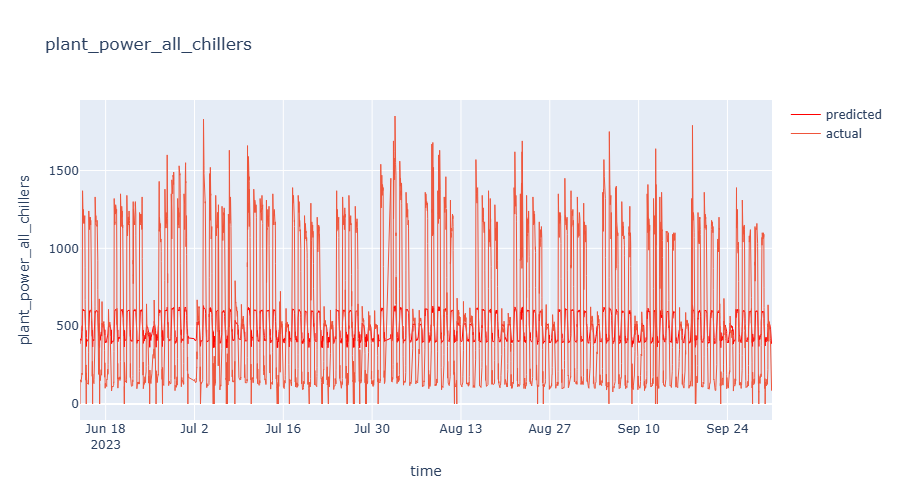

X_train shape: (46206, 20)
X_train_scaled shape before reshape: (46206, 20)
Expected reshape dimensions: (46206, 4, 5)
Epoch [1/10], Loss: 0.9098
Epoch [2/10], Loss: 0.8825
Epoch [3/10], Loss: 0.8557
Epoch [4/10], Loss: 0.8292
Epoch [5/10], Loss: 0.8029
Epoch [6/10], Loss: 0.7769
Epoch [7/10], Loss: 0.7510
Epoch [8/10], Loss: 0.7252
Epoch [9/10], Loss: 0.6995
Epoch [10/10], Loss: 0.6738
NARX MSE for plant_power_all_cts: 223.13485717773438
NARX MSE after Clipping for plant_power_all_cts: 223.13485717773438


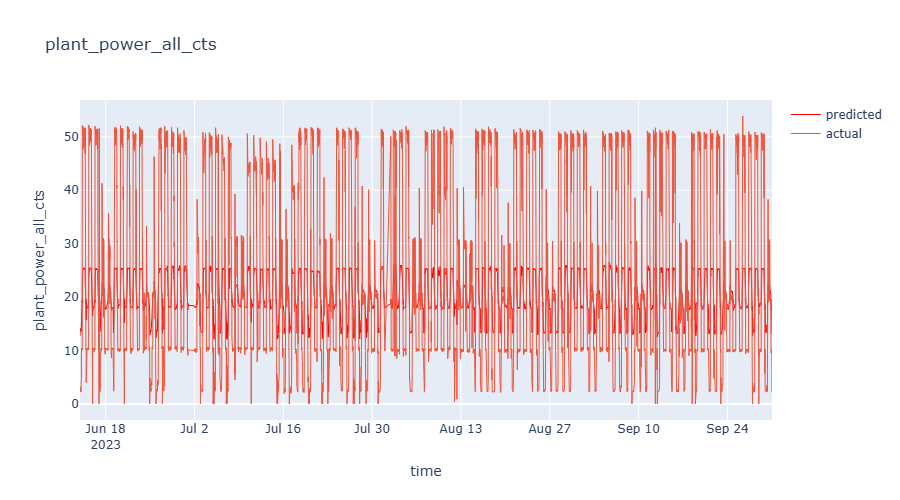

In [73]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import plotly.express as px
import plotly.graph_objects as go

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define the function to create lagged features
def create_lagged_features(df, target_col, lag, exog_cols):
    # Group columns by timestep, oldest first, so the frame reshapes to
    # (samples, lag + 1, features). Each step is the target, then the exogenous
    # inputs. The current target is the label, so the last step repeats the
    # previous target.
    columns = {target_col: df[target_col]}
    for offset in range(lag, -1, -1):
        step = lag - offset
        target_offset = offset if offset > 0 else 1
        columns[f'{target_col}_step{step}'] = df[target_col].shift(target_offset)
        for exog_col in exog_cols:
            columns[f'{exog_col}_step{step}'] = df[exog_col].shift(offset)
    return pd.DataFrame(columns, index=df.index).dropna()

# Parameters
lag = 3  # Number of lags to use

plant_features = {'plant_power': ['condenser_water_loop_flow_rate',
                                  'chilled_water_loop_flow_rate',
                                  'condenser_water_loop_water_delta_temperature',
                                  'chilled_water_loop_water_delta_temperature',
                                  'plant_number_of_running_chps'],
                  'plant_power_all_cdps': ['plant_avg_cdp_speed',
                                           'condenser_water_loop_flow_rate'],
                  'plant_power_all_chps': ['plant_avg_chp_speed',
                                           'chilled_water_loop_flow_rate'],
                  'plant_power_all_chillers': ['condenser_water_loop_flow_rate',
                                               'chilled_water_loop_flow_rate',
                                               'condenser_water_loop_water_delta_temperature',
                                               'chilled_water_loop_water_delta_temperature'],
                  'plant_power_all_cts': ['condenser_water_loop_flow_rate',
                                          'plant_number_of_running_cts',
                                          'plant_avg_ct_speed',
                                          'condenser_water_loop_water_delta_temperature']}

plant_targets = [[col] for col in chiller_data_fit.columns if 'plant' in col and 'power' in col]

class NARXModel(nn.Module):
    def __init__(self, input_dim):
        super(NARXModel, self).__init__()
        self.lstm = nn.LSTM(input_dim, 50, batch_first=True)
        self.fc = nn.Linear(50, 1)

    def forward(self, x):
        x, _ = self.lstm(x)
        x = x[:, -1, :]
        x = self.fc(x)
        return x

for target in plant_targets:
    target_col = target[0]
    exog_cols = plant_features[target_col]

    use_cols = [col for col in chiller_data_fit.columns if col==target_col or col in exog_cols]
    df_use = chiller_data_fit[use_cols]

    # Create lagged features
    df_use_lagged = create_lagged_features(df_use, target_col, lag, exog_cols)
    X = df_use_lagged.drop(columns=[target_col])
    y = df_use_lagged[target]

    # Splitting the data into train and test sets
    train_size = int(0.6 * len(X))
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    # Normalize the features
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled = scaler_X.transform(X_test)
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
    y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

    # One feature group per timestep: previous target plus the exogenous inputs
    num_features = 1 + len(exog_cols)
    timesteps = lag + 1

    print(f"X_train shape: {X_train.shape}")
    print(f"X_train_scaled shape before reshape: {X_train_scaled.shape}")
    print(f"Expected reshape dimensions: ({X_train_scaled.shape[0]}, {timesteps}, {num_features})")

    if X_train_scaled.shape[1] != timesteps * num_features:
        raise ValueError(f"Cannot reshape array of size {X_train_scaled.size} into shape ({X_train_scaled.shape[0]}, {timesteps}, {num_features})")

    # Reshape for LSTM
    X_train_scaled = X_train_scaled.reshape((X_train_scaled.shape[0], timesteps, num_features))
    X_test_scaled = X_test_scaled.reshape((X_test_scaled.shape[0], timesteps, num_features))

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)

    # Define the model
    model = NARXModel(input_dim=X_train_tensor.shape[2]).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Training the model
    num_epochs = 10
    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train_tensor)
        loss = criterion(outputs, y_train_tensor)
        loss.backward()
        optimizer.step()

        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

    # Make predictions
    model.eval()
    with torch.no_grad():
        y_pred_scaled = model(X_test_tensor).cpu().numpy()
        y_pred = scaler_y.inverse_transform(y_pred_scaled)

    # Clipping negative predictions to zero
    y_pred_clipped = y_pred.clip(min=0)

    # Calculate MSE
    mse = mean_squared_error(y_test, y_pred)
    mse_clipped = mean_squared_error(y_test, y_pred_clipped)
    print(f"NARX MSE for {target_col}: {mse}")
    print(f"NARX MSE after Clipping for {target_col}: {mse_clipped}")

    # Visualize the results. Timestamp text cannot be placed on a Plotly axis.
    x_plot = X_test.index
    if not isinstance(x_plot, pd.DatetimeIndex):
        x_plot = pd.to_datetime(x_plot, utc=True).tz_convert('Asia/Bangkok')
    if getattr(x_plot, 'tz', None) is not None:
        x_plot = x_plot.tz_convert('Asia/Bangkok').tz_localize(None)
    pred_plot = np.asarray(y_pred_clipped).ravel()
    actual_plot = np.asarray(y_test[target_col]).ravel()
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x_plot, y=pred_plot, mode='lines', name='predicted', line=dict(color='red', width=1)))
    fig.add_trace(go.Scatter(x=x_plot, y=actual_plot, mode='lines', name='actual', line=dict(width=1)))
    fig.update_layout(title=target_col, xaxis_title='time', yaxis_title=target_col)
    fig.show()


In [74]:

import torch

print(f"PyTorch: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA version: {torch.version.cuda}")

if torch.cuda.is_available():
    cuda_id = torch.cuda.current_device()
    print(f"ID of current CUDA device: {cuda_id}")
    print(f"Name of current CUDA device: {torch.cuda.get_device_name(cuda_id)}")
else:
    print("No CUDA device is available to this PyTorch build. Training will use the CPU.")

PyTorch: 2.11.0+cu128
CUDA available: True
CUDA version: 12.8
ID of current CUDA device: 0
Name of current CUDA device: NVIDIA GeForce RTX 3050 Laptop GPU


Using device: cuda


Epoch [1/10], Loss: 1.0172
Epoch [2/10], Loss: 0.9228
Epoch [3/10], Loss: 0.8318
Epoch [4/10], Loss: 0.7423
Epoch [5/10], Loss: 0.6557
Epoch [6/10], Loss: 0.5728
Epoch [7/10], Loss: 0.4936
Epoch [8/10], Loss: 0.4182
Epoch [9/10], Loss: 0.3473
Epoch [10/10], Loss: 0.2816
NARX MSE for plant_power: 57561.4765625
NARX MSE after Clipping for plant_power: 57561.4765625


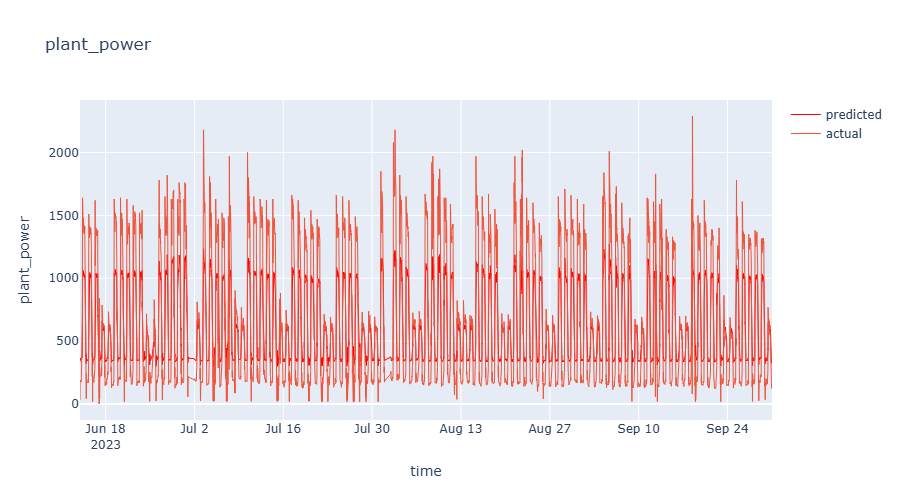

Epoch [1/10], Loss: 0.8515
Epoch [2/10], Loss: 0.7746
Epoch [3/10], Loss: 0.7016
Epoch [4/10], Loss: 0.6335
Epoch [5/10], Loss: 0.5690
Epoch [6/10], Loss: 0.5103
Epoch [7/10], Loss: 0.4556
Epoch [8/10], Loss: 0.4041
Epoch [9/10], Loss: 0.3565
Epoch [10/10], Loss: 0.3129
NARX MSE for plant_power_all_cdps: 321.66754150390625
NARX MSE after Clipping for plant_power_all_cdps: 321.66754150390625


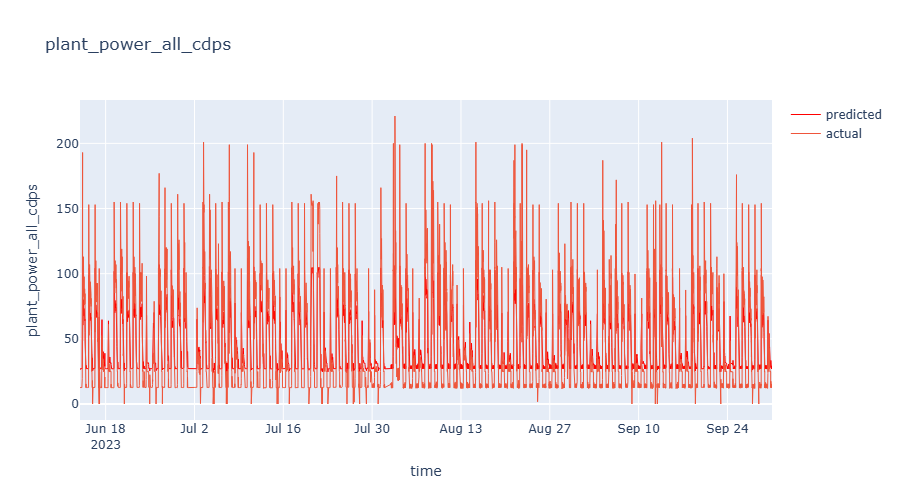

Epoch [1/10], Loss: 1.1974
Epoch [2/10], Loss: 1.0999
Epoch [3/10], Loss: 1.0061
Epoch [4/10], Loss: 0.9159
Epoch [5/10], Loss: 0.8291
Epoch [6/10], Loss: 0.7459
Epoch [7/10], Loss: 0.6662
Epoch [8/10], Loss: 0.5907
Epoch [9/10], Loss: 0.5202
Epoch [10/10], Loss: 0.4548
NARX MSE for plant_power_all_chps: 219.35789489746094
NARX MSE after Clipping for plant_power_all_chps: 219.35789489746094


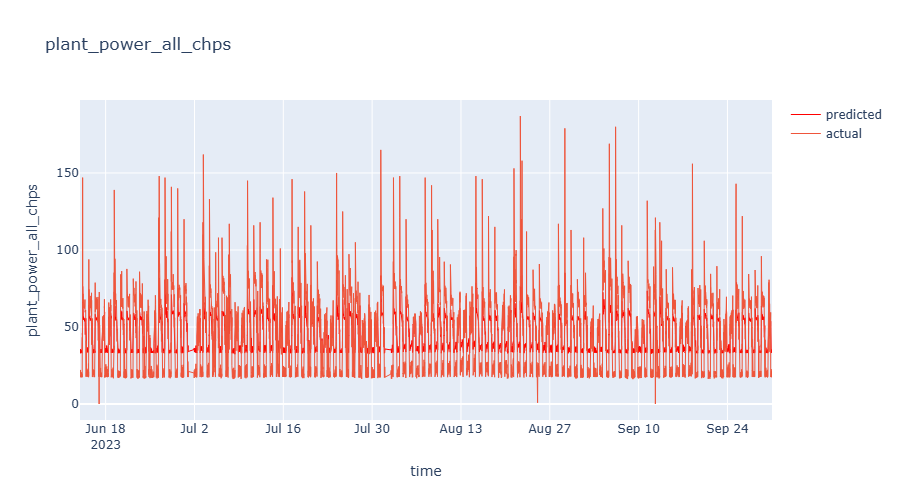

Epoch [1/10], Loss: 0.8980
Epoch [2/10], Loss: 0.8082
Epoch [3/10], Loss: 0.7242
Epoch [4/10], Loss: 0.6447
Epoch [5/10], Loss: 0.5694
Epoch [6/10], Loss: 0.4990
Epoch [7/10], Loss: 0.4339
Epoch [8/10], Loss: 0.3732
Epoch [9/10], Loss: 0.3166
Epoch [10/10], Loss: 0.2641
NARX MSE for plant_power_all_chillers: 34369.2734375
NARX MSE after Clipping for plant_power_all_chillers: 34369.2734375


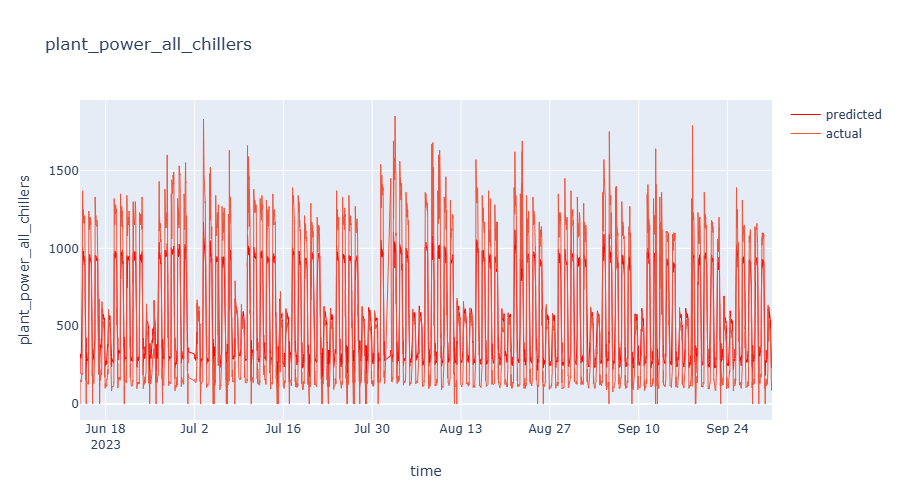

Epoch [1/10], Loss: 1.3025
Epoch [2/10], Loss: 1.1634
Epoch [3/10], Loss: 1.0397
Epoch [4/10], Loss: 0.9269
Epoch [5/10], Loss: 0.8233
Epoch [6/10], Loss: 0.7289
Epoch [7/10], Loss: 0.6431
Epoch [8/10], Loss: 0.5666
Epoch [9/10], Loss: 0.4991
Epoch [10/10], Loss: 0.4402
NARX MSE for plant_power_all_cts: 127.60874938964844
NARX MSE after Clipping for plant_power_all_cts: 127.60554504394531


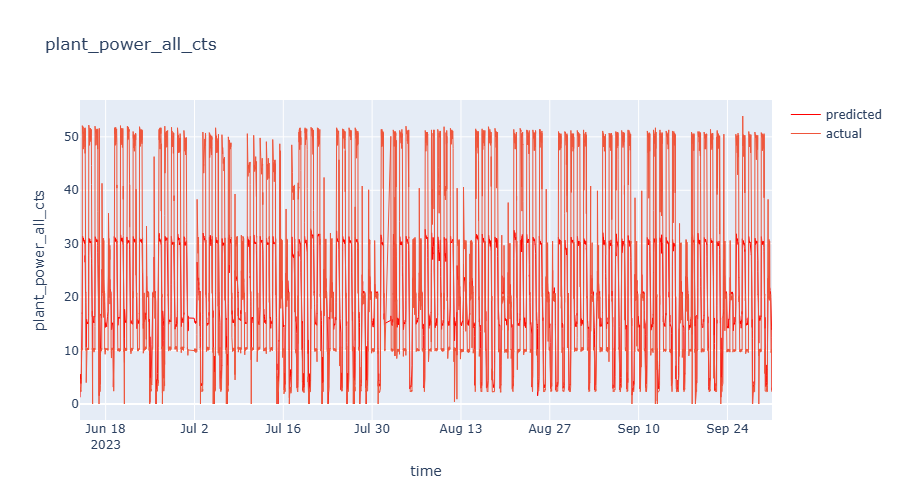

In [75]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
import plotly.express as px
import plotly.graph_objects as go

# Check if GPU is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define the function to create lagged features
def create_lagged_features(df, target_col, lag, exog_cols):
    df_lagged = df.copy()
    for l in range(1, lag + 1):
        df_lagged[f'{target_col}_lag{l}'] = df[target_col].shift(l)
        for exog_col in exog_cols:
            df_lagged[f'{exog_col}_lag{l}'] = df[exog_col].shift(l)
    df_lagged = df_lagged.dropna()
    return df_lagged

# Parameters
lag = 3  # Number of lags to use

plant_features = {'plant_power': ['condenser_water_loop_flow_rate',
                                  'chilled_water_loop_flow_rate',
                                  'condenser_water_loop_water_delta_temperature',
                                  'chilled_water_loop_water_delta_temperature',
                                  'plant_number_of_running_chps'],
                  'plant_power_all_cdps': ['plant_avg_cdp_speed',
                                           'condenser_water_loop_flow_rate'],
                  'plant_power_all_chps': ['plant_avg_chp_speed',
                                           'chilled_water_loop_flow_rate'],
                  'plant_power_all_chillers': ['condenser_water_loop_flow_rate',
                                               'chilled_water_loop_flow_rate',
                                               'condenser_water_loop_water_delta_temperature',
                                               'chilled_water_loop_water_delta_temperature'],
                  'plant_power_all_cts': ['condenser_water_loop_flow_rate',
                                          'plant_number_of_running_cts',
                                          'plant_avg_ct_speed',
                                          'condenser_water_loop_water_delta_temperature']}

plant_targets = [[col] for col in chiller_data_fit.columns if 'plant' in col and 'power' in col]

class NARXModel(nn.Module):
    def __init__(self, input_dim):
        super(NARXModel, self).__init__()
        self.fc1 = nn.Linear(input_dim, 100)
        self.fc2 = nn.Linear(100, 50)
        self.fc3 = nn.Linear(50, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.fc3(x)
        return x

for target in plant_targets:
    target_col = target[0]
    exog_cols = plant_features[target_col]

    use_cols = [col for col in chiller_data_fit.columns if col==target_col or col in exog_cols]
    df_use = chiller_data_fit[use_cols]

    # Create lagged features
    df_use_lagged = create_lagged_features(df_use, target_col, lag, exog_cols)
    X = df_use_lagged.drop(columns=[target_col])
    y = df_use_lagged[target]

    # Splitting the data into train and test sets
    train_size = int(0.6 * len(X))
    X_train, X_test = X[:train_size], X[train_size:]
    y_train, y_test = y[:train_size], y[train_size:]

    # Normalize the features
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled = scaler_X.transform(X_test)
    y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
    y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))

    # Convert to PyTorch tensors
    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).to(device)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).to(device)

    # Define the model
    model = NARXModel(input_dim=X_train_tensor.shape[1]).to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Training the model
    num_epochs = 10
    for epoch in range(num_epochs):
        model.train()
        optimizer.zero_grad()
        outputs = model(X_train_tensor)
        loss = criterion(outputs, y_train_tensor)
        loss.backward()
        optimizer.step()

        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

    # Make predictions
    model.eval()
    with torch.no_grad():
        y_pred_scaled = model(X_test_tensor).cpu().numpy()
        y_pred = scaler_y.inverse_transform(y_pred_scaled)

    # Clipping negative predictions to zero
    y_pred_clipped = y_pred.clip(min=0)

    # Calculate MSE
    mse = mean_squared_error(y_test, y_pred)
    mse_clipped = mean_squared_error(y_test, y_pred_clipped)
    print(f"NARX MSE for {target_col}: {mse}")
    print(f"NARX MSE after Clipping for {target_col}: {mse_clipped}")

    # Visualize the results. Timestamp text cannot be placed on a Plotly axis.
    x_plot = X_test.index
    if not isinstance(x_plot, pd.DatetimeIndex):
        x_plot = pd.to_datetime(x_plot, utc=True).tz_convert('Asia/Bangkok')
    if getattr(x_plot, 'tz', None) is not None:
        x_plot = x_plot.tz_convert('Asia/Bangkok').tz_localize(None)
    pred_plot = np.asarray(y_pred_clipped).ravel()
    actual_plot = np.asarray(y_test[target_col]).ravel()
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=x_plot, y=pred_plot, mode='lines', name='predicted', line=dict(color='red', width=1)))
    fig.add_trace(go.Scatter(x=x_plot, y=actual_plot, mode='lines', name='actual', line=dict(width=1)))
    fig.update_layout(title=target_col, xaxis_title='time', yaxis_title=target_col)
    fig.show()
